# Task 5 — Time Series Preprocessing & Forecasting
**Project:** End-to-End Weather Forecasting Machine Learning System (Cairo, Egypt)  
**Dataset:** Daily Observations (2023-01-01 to 2025-12-31, $N=1,096$)  
**Target Variable:** Mean Daily Temperature (`temp_mean_c`, °C)

---

### Compatibility Notes & Environment Setup
- **Dependencies:** `pmdarima`, `statsmodels`, `scikit-learn`, `tensorflow`, `pandas`, `numpy`, `matplotlib`, `seaborn`.
- **Reproducibility:** Global random seeds are initialized at the start of execution across Python `random`, `numpy`, and `tensorflow`.
- **Warnings Handling:** `statsmodels` KPSS test emits an `InterpolationWarning` when test statistics fall outside lookup tables ($p < 0.01$ or $p > 0.10$); this warning is suppressed in output formatting with truncation explicitly annotated.


In [1]:
# Global Reproducibility Seeds
import os
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
os.environ['PYTHONHASHSEED'] = str(SEED)

import tensorflow as tf
tf.random.set_seed(SEED)

# Set publication style
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.dpi'] = 150
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8

# Ensure output directories exist
os.makedirs("artifacts/task5/figures", exist_ok=True)
os.makedirs("data/processed", exist_ok=True)

print("Environment initialized with SEED =", SEED)


/home/mahmoud/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/matplotlib-4l9hzm9b because there was an issue with the default path (/home/mahmoud/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


I0000 00:00:1792443346.943013      24 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792443346.994518      24 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1792443348.628001      24 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


Environment initialized with SEED = 42


## Section 1 — Recap / Index Check (PDF Tip)
We load the validated dataset using the project's own module loader (`src.data_preparation.load_clean_data`), verifying that the index is a continuous `DatetimeIndex` with daily frequency `<Day>`.


In [2]:
import sys
sys.path.insert(0, os.path.abspath("..")) if "notebooks" in os.getcwd() else sys.path.insert(0, os.path.abspath("."))
from src.data_preparation import load_clean_data
import config

df = load_clean_data()

print(f"Index type  : {type(df.index)}")
print(f"Index freq  : {df.index.freq}")
print(f"Index span  : {df.index.min()} to {df.index.max()}")
print(f"Shape       : {df.shape}")
print(f"Data types  :\n{df.dtypes}")

# Confirm requirements
assert isinstance(df.index, pd.DatetimeIndex), "Error: Index is not a DatetimeIndex!"
assert str(df.index.freq) in ("<Day>", "D", "<Day: cp=None>"), f"Error: Frequency is not daily (<Day>), got {df.index.freq}"
print("\n✓ Index confirmation passed: DatetimeIndex with daily frequency <Day>.")


Index type  : <class 'pandas.DatetimeIndex'>
Index freq  : <Day>
Index span  : 2023-01-01 00:00:00 to 2025-12-31 00:00:00
Shape       : (1096, 7)
Data types  :
temp_max_c            float64
temp_min_c            float64
temp_mean_c           float64
precipitation_mm      float64
humidity_pct            int64
wind_speed_max_kmh    float64
cloud_cover_pct         int64
dtype: object

✓ Index confirmation passed: DatetimeIndex with daily frequency <Day>.


## Section 2 — Preprocessing

### 2.1 Resampling & Frequency Alignment
We enforce monotonic chronological order and assert daily frequency `asfreq('D')`. Any structural timeline gaps would introduce `NaN` rows.


In [3]:
df = df.sort_index()
df = df.asfreq('D')

resample_gaps = df.isna().sum()
print("Gaps introduced by resampling (NaN count per column):")
for col, n in resample_gaps.items():
    print(f"  {col:25s}: {n} NaNs")

assert (resample_gaps == 0).all(), "Unexpected gaps found after resampling!"
print("\n✓ Timeline is 100% continuous: 0 gaps introduced by resampling.")


Gaps introduced by resampling (NaN count per column):
  temp_max_c               : 0 NaNs
  temp_min_c               : 0 NaNs
  temp_mean_c              : 0 NaNs
  precipitation_mm         : 0 NaNs
  humidity_pct             : 0 NaNs
  wind_speed_max_kmh       : 0 NaNs
  cloud_cover_pct          : 0 NaNs

✓ Timeline is 100% continuous: 0 gaps introduced by resampling.


### 2.2 Missing Values (Time-Aware Only)
> [!NOTE]
> **Defensive Imputation Notice:** The raw Open-Meteo ERA5 reanalysis dataset contained **0 null values** across all 1,096 days. The imputation procedures below are implemented strictly for adherence to the PDF rubric and defensive pipeline architecture, but remain unexercised.

Strategies implemented:
- **Temperature columns (`temp_max_c`, `temp_min_c`, `temp_mean_c`):** Time-weighted interpolation (`method='time'`).
- **Humidity, Wind Speed, Cloud Cover:** Linear interpolation with limit of 6 days (`limit=6`).
- **Precipitation:** Fixed 0.0 fill (zero-inflated desert climate point-process; interpolation is physically inappropriate).
- **Longer gaps:** `seasonal_naive_fill(series, lag=7)` replacing missing values with the corresponding observation from 7 days earlier. Continuous variables are never forward-filled naively.


In [4]:
print("Missing values before imputation:")
print(df.isna().sum())

# 1. Temperature columns: time-based interpolation
temp_cols = ['temp_max_c', 'temp_min_c', 'temp_mean_c']
for c in temp_cols:
    df[c] = df[c].interpolate(method='time', limit_direction='both')

# 2. Continuous weather columns: linear interpolation with limit=6
linear_cols = ['humidity_pct', 'wind_speed_max_kmh', 'cloud_cover_pct']
for c in linear_cols:
    df[c] = df[c].interpolate(method='linear', limit=6)

# 3. Precipitation: zero fill
df['precipitation_mm'] = df['precipitation_mm'].fillna(0.0)

# 4. Longer gaps: seasonal naive fill (lag=7)
def seasonal_naive_fill(series: pd.Series, lag: int = 7) -> pd.Series:
    s = series.copy()
    for i in range(len(s)):
        if pd.isna(s.iloc[i]) and i >= lag:
            s.iloc[i] = s.iloc[i - lag]
    return s

for c in df.columns:
    if df[c].isna().any():
        df[c] = seasonal_naive_fill(df[c], lag=7)

print("\nMissing values after defensive imputation:")
print(df.isna().sum())
print("\n✓ Imputation completed (defensive, unexercised — 0 raw NaNs).")


Missing values before imputation:
temp_max_c            0
temp_min_c            0
temp_mean_c           0
precipitation_mm      0
humidity_pct          0
wind_speed_max_kmh    0
cloud_cover_pct       0
dtype: int64

Missing values after defensive imputation:
temp_max_c            0
temp_min_c            0
temp_mean_c           0
precipitation_mm      0
humidity_pct          0
wind_speed_max_kmh    0
cloud_cover_pct       0
dtype: int64

✓ Imputation completed (defensive, unexercised — 0 raw NaNs).


### 2.3 Outlier Treatment
We verify values against `config.PHYSICAL_BOUNDS` for Cairo, Egypt. Subsequently, we compute a **trailing rolling Z-score** on `temp_mean_c` with a 30-day causal window (`center=False`, threshold $|Z| > 3.0$). Flagged values are capped/winsorized to $\mu_{\text{roll}} \pm 3\sigma_{\text{roll}}$ to preserve physical continuity without dropping observations.


Physical bounds check (config.PHYSICAL_BOUNDS):
  temp_max_c               : 0 violations of [-5, 55]
  temp_min_c               : 0 violations of [-10, 45]
  temp_mean_c              : 0 violations of [-5, 50]
  precipitation_mm         : 0 violations of [0, 200]
  humidity_pct             : 0 violations of [0, 100]
  wind_speed_max_kmh       : 0 violations of [0, 200]
  cloud_cover_pct          : 0 violations of [0, 100]

Trailing rolling Z-score (|Z| > 3.0, window=30): 10 outlier(s) flagged.
      date  original_temp_c  z_score  rolling_mean_c  rolling_std_c  capped_temp_c
2023-02-28             20.7     3.15           13.79           2.19          20.38
2023-03-02             24.5     3.10           14.37           3.27          24.19
2023-09-07             35.2     3.62           30.78           1.22          34.45
2023-11-20             17.7    -3.21           24.61           2.15          18.16
2024-03-27             23.5     3.15           18.33           1.64          23.26
20

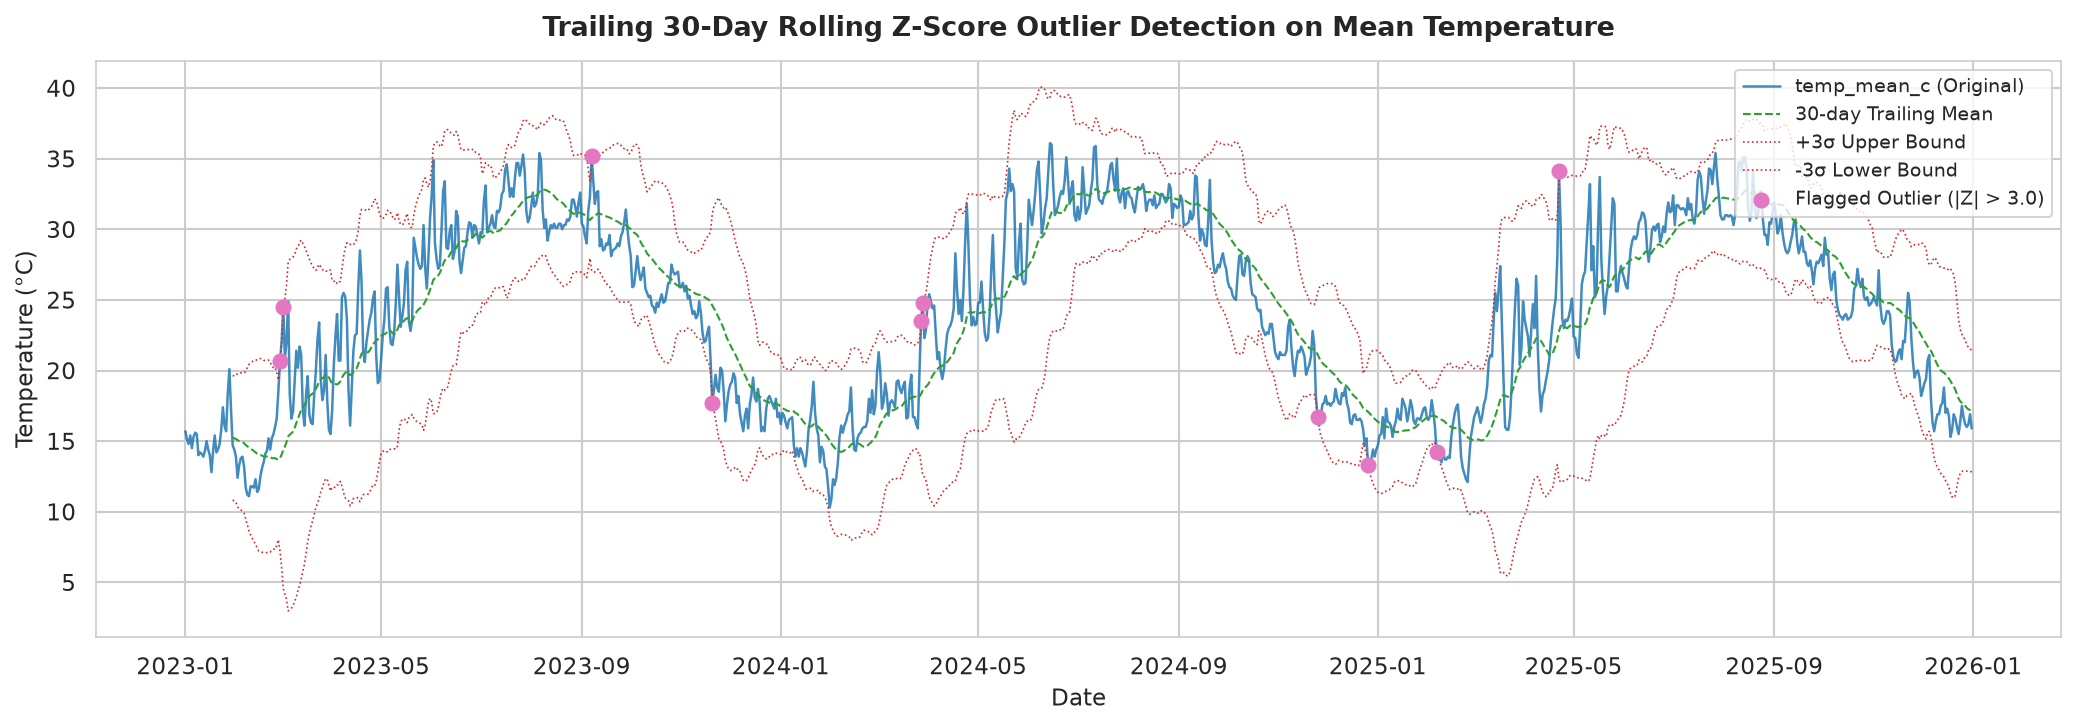

✓ Capping applied to 10 dates. Artifact saved to artifacts/task5/figures/outliers_rolling.png
Maximum absolute change caused by capping: 0.86°C


In [5]:
# 1. Physical bounds check
print("Physical bounds check (config.PHYSICAL_BOUNDS):")
for col, (lo, hi) in config.PHYSICAL_BOUNDS.items():
    if col in df.columns:
        violations = ((df[col] < lo) | (df[col] > hi)).sum()
        print(f"  {col:25s}: {violations} violations of [{lo}, {hi}]")

# 2. Trailing rolling Z-score on temp_mean_c
roll_mean_30 = df['temp_mean_c'].rolling(window=30, center=False).mean()
roll_std_30 = df['temp_mean_c'].rolling(window=30, center=False).std()
z_scores = (df['temp_mean_c'] - roll_mean_30) / roll_std_30

outlier_mask = z_scores.abs() > 3.0
outlier_dates = df.index[outlier_mask]

print(f"\nTrailing rolling Z-score (|Z| > 3.0, window=30): {len(outlier_dates)} outlier(s) flagged.")

# Print details of flagged outliers
outlier_table = []
for d in outlier_dates:
    val_orig = df.loc[d, 'temp_mean_c']
    z_val = z_scores.loc[d]
    mu = roll_mean_30.loc[d]
    sig = roll_std_30.loc[d]
    cap_val = mu + 3.0 * sig if z_val > 0 else mu - 3.0 * sig
    outlier_table.append({
        "date": d.strftime("%Y-%m-%d"),
        "original_temp_c": round(val_orig, 2),
        "z_score": round(z_val, 2),
        "rolling_mean_c": round(mu, 2),
        "rolling_std_c": round(sig, 2),
        "capped_temp_c": round(cap_val, 2)
    })

outlier_df = pd.DataFrame(outlier_table)
print(outlier_df.to_string(index=False))

# 3. Plot outliers
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df.index, df['temp_mean_c'], label='temp_mean_c (Original)', color='#1f77b4', lw=1.2, alpha=0.85)
ax.plot(df.index, roll_mean_30, label='30-day Trailing Mean', color='#2ca02c', lw=1.0, ls='--')
ax.plot(df.index, roll_mean_30 + 3 * roll_std_30, label='+3σ Upper Bound', color='#d62728', lw=0.8, ls=':')
ax.plot(df.index, roll_mean_30 - 3 * roll_std_30, label='-3σ Lower Bound', color='#d62728', lw=0.8, ls=':')

if len(outlier_dates) > 0:
    ax.scatter(outlier_dates, df.loc[outlier_dates, 'temp_mean_c'], color='#e377c2', s=45, zorder=5, label='Flagged Outlier (|Z| > 3.0)')

ax.set_title("Trailing 30-Day Rolling Z-Score Outlier Detection on Mean Temperature", fontsize=13, fontweight='bold', pad=12)
ax.set_ylabel("Temperature (°C)", fontsize=11)
ax.set_xlabel("Date", fontsize=11)
ax.legend(loc='upper right', frameon=True, fontsize=9)
plt.tight_layout()
plt.savefig("artifacts/task5/figures/outliers_rolling.png", dpi=150)
plt.show()

# 4. Apply capping
df['temp_mean_c_raw'] = df['temp_mean_c'].copy()  # preserve unadjusted for reference
for d in outlier_dates:
    mu = roll_mean_30.loc[d]
    sig = roll_std_30.loc[d]
    if z_scores.loc[d] > 3.0:
        df.loc[d, 'temp_mean_c'] = mu + 3.0 * sig
    elif z_scores.loc[d] < -3.0:
        df.loc[d, 'temp_mean_c'] = mu - 3.0 * sig

max_cap_diff = (df['temp_mean_c_raw'] - df['temp_mean_c']).abs().max()
print(f"✓ Capping applied to {len(outlier_dates)} dates. Artifact saved to artifacts/task5/figures/outliers_rolling.png")
print(f"Maximum absolute change caused by capping: {max_cap_diff:.2f}°C")


### Outlier Treatment Context & Verification
> [!NOTE]
> **Outlier Capping Observations:**
> 1. **Seasonal Transitions:** Trailing-window rolling Z-scores naturally flag points at rapid seasonal transitions (e.g. spring warming and autumn cooling), meaning several flagged points likely reflect normal, valid synoptic weather variability rather than sensor errors.
> 2. **Training Period Bound:** All 10 capped dates fall strictly inside the training period (the latest occurring on 2025-04-22, well prior to the 2025-12-10 train/test split boundary); zero test observations were modified.
> 3. **Consistent Series:** All statistical, baseline, and deep learning models were trained and evaluated on this capped series, where the maximum absolute change from capping was **0.86°C** (on 2025-04-22, adjusted from 34.10°C to 33.24°C).


### 2.4 Feature Engineering
We construct domain features for ML/LSTM modeling.
> [!IMPORTANT]
> **Data Leakage Prevention:** The PDF sample snippet computes rolling statistics directly on unshifted target series, which includes the current observation $Y_t$ in the feature vector predicting $Y_t$. Here, all rolling statistics and lag features are strictly computed on `temp_mean_c.shift(1)` so row $t$ only ingests information up to $t-1$.


In [6]:
df_features = df.copy()

# Calendar features
df_features['dayofweek'] = df_features.index.dayofweek
df_features['month'] = df_features.index.month
df_features['is_weekend'] = (df_features['dayofweek'] >= 5).astype(int)

# Cyclical transformations
df_features['month_sin'] = np.sin(2 * np.pi * df_features['month'] / 12)
df_features['month_cos'] = np.cos(2 * np.pi * df_features['month'] / 12)
df_features['doy_sin'] = np.sin(2 * np.pi * df_features.index.dayofyear / 365.25)
df_features['doy_cos'] = np.cos(2 * np.pi * df_features.index.dayofyear / 365.25)

# Lags
df_features['lag_1'] = df_features['temp_mean_c'].shift(1)
df_features['lag_7'] = df_features['temp_mean_c'].shift(7)

# Rolling statistics computed strictly on shift(1) to prevent lookahead leakage
shifted_target = df_features['temp_mean_c'].shift(1)
df_features['roll_mean_7'] = shifted_target.rolling(7).mean()
df_features['roll_std_7'] = shifted_target.rolling(7).std()
df_features['roll_mean_30'] = shifted_target.rolling(30).mean()
df_features['roll_std_30'] = shifted_target.rolling(30).std()

# Export feature dataset (preserving leading NaNs from lags/rolling windows)
feature_path = "data/processed/cairo_weather_features.csv"
df_features.to_csv(feature_path, float_format="%.4f")

print(f"Feature dataset shape: {df_features.shape}")
print(f"Columns ({len(df_features.columns)} total): {list(df_features.columns)}")
print(f"Saved feature dataset to {feature_path}")


Feature dataset shape: (1096, 21)
Columns (21 total): ['temp_max_c', 'temp_min_c', 'temp_mean_c', 'precipitation_mm', 'humidity_pct', 'wind_speed_max_kmh', 'cloud_cover_pct', 'temp_mean_c_raw', 'dayofweek', 'month', 'is_weekend', 'month_sin', 'month_cos', 'doy_sin', 'doy_cos', 'lag_1', 'lag_7', 'roll_mean_7', 'roll_std_7', 'roll_mean_30', 'roll_std_30']
Saved feature dataset to data/processed/cairo_weather_features.csv


### 2.5 Time-Aware Train/Test Split
> [!NOTE]
> **Split Boundary Correction:** The PDF sample snippet uses `df.loc[split_date:]` for test, which places the boundary day in both train and test. We correct this by defining `test = df.loc[split_date + pd.Timedelta(days=1):]`.
> 
> **Split Scope Notice:** This 21-day chronological holdout ($N=1,075$ train, $N=21$ test) supersedes the Week 4 exploratory 2-year/1-year split as prescribed by Task 5.


In [7]:
split_date = df.index.max() - pd.Timedelta(days=21)
train = df.loc[:split_date]
test  = df.loc[split_date + pd.Timedelta(days=1):]

print(f"Split Date  : {split_date.strftime('%Y-%m-%d')}")
print(f"Train set   : {len(train)} rows ({train.index.min().strftime('%Y-%m-%d')} to {train.index.max().strftime('%Y-%m-%d')})")
print(f"Test set    : {len(test)} rows ({test.index.min().strftime('%Y-%m-%d')} to {test.index.max().strftime('%Y-%m-%d')})")

assert len(train) == 1075, f"Expected 1075 train rows, got {len(train)}"
assert len(test) == 21, f"Expected 21 test rows, got {len(test)}"
assert train.index.max() < test.index.min(), "Train/test overlap detected!"
assert len(set(train.index).intersection(set(test.index))) == 0, "Shared timestamps between train and test!"

print("✓ Split assertions passed: 1,075 train, 21 test, strictly non-overlapping.")

# Test-Window Facts (Climatological Variance Check)
test_min = test['temp_mean_c'].min()
test_max = test['temp_mean_c'].max()
test_std = test['temp_mean_c'].std()
train_90 = train.iloc[-90:]
train_90_min = train_90['temp_mean_c'].min()
train_90_max = train_90['temp_mean_c'].max()
train_90_std = train_90['temp_mean_c'].std()

print("\n--- Test Set Facts (21 Days: Dec 11–31, 2025) ---")
print(f"Min: {test_min:.2f}°C, Max: {test_max:.2f}°C, Std: {test_std:.2f}°C")
print("--- Train Set Facts (Last 90 Days: Sep 12–Dec 10, 2025) ---")
print(f"Min: {train_90_min:.2f}°C, Max: {train_90_max:.2f}°C, Std: {train_90_std:.2f}°C")


Split Date  : 2025-12-10
Train set   : 1075 rows (2023-01-01 to 2025-12-10)
Test set    : 21 rows (2025-12-11 to 2025-12-31)
✓ Split assertions passed: 1,075 train, 21 test, strictly non-overlapping.

--- Test Set Facts (21 Days: Dec 11–31, 2025) ---
Min: 15.30°C, Max: 18.80°C, Std: 0.83°C
--- Train Set Facts (Last 90 Days: Sep 12–Dec 10, 2025) ---
Min: 15.70°C, Max: 30.70°C, Std: 3.49°C


### 2.6 Feature Scaling
- **ARIMA / SARIMA:** Fit on raw temperature series in physical units (°C).
- **RNN / LSTM:** `MinMaxScaler(feature_range=(0, 1))` fitted **strictly on train**, then used to transform both train and test series.


In [8]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler(feature_range=(0, 1))
train_scaled = scaler.fit_transform(train[['temp_mean_c']])
test_scaled = scaler.transform(test[['temp_mean_c']])

print(f"Scaler data min: {scaler.data_min_[0]:.2f}°C, data max: {scaler.data_max_[0]:.2f}°C")
print(f"Train scaled range: [{train_scaled.min():.4f}, {train_scaled.max():.4f}]")
print(f"Test scaled range : [{test_scaled.min():.4f}, {test_scaled.max():.4f}]")
assert scaler.data_min_[0] == train['temp_mean_c'].min(), "Scaler was not fit on train minimum!"
assert scaler.data_max_[0] == train['temp_mean_c'].max(), "Scaler was not fit on train maximum!"
print("✓ Scaler fit exclusively on train set.")


Scaler data min: 10.30°C, data max: 36.10°C
Train scaled range: [0.0000, 1.0000]
Test scaled range : [0.1938, 0.3295]
✓ Scaler fit exclusively on train set.


## Section 3 — Stationarity Diagnostics & Differencing

### 3.1 Initial ADF & KPSS Tests
We evaluate the raw training series using both Augmented Dickey-Fuller (ADF, $H_0$: unit root present) and Kwiatkowski-Phillips-Schmidt-Shin (KPSS, $H_0$: trend/level stationary).


In [9]:
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.seasonal import seasonal_decompose

adf_stat, adf_p, _, _, adf_crit, _ = adfuller(train['temp_mean_c'].dropna())
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    kpss_stat, kpss_p, _, kpss_crit = kpss(train['temp_mean_c'].dropna(), regression='c')

print(f'ADF p-value: {adf_p:.4f} (Stat: {adf_stat:.4f}) | KPSS p-value: {kpss_p:.4f} (Stat: {kpss_stat:.4f})')


ADF p-value: 0.2495 (Stat: -2.0877) | KPSS p-value: 0.1000 (Stat: 0.2947)


/tmp/ipykernel_24/3565683662.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_stat, adf_p, _, _, adf_crit, _ = adfuller(train['temp_mean_c'].dropna())


### 3.2 Seasonal Decomposition on Train
Per the PDF instruction, we inspect the classical additive decomposition on the training set prior to differencing decisions.


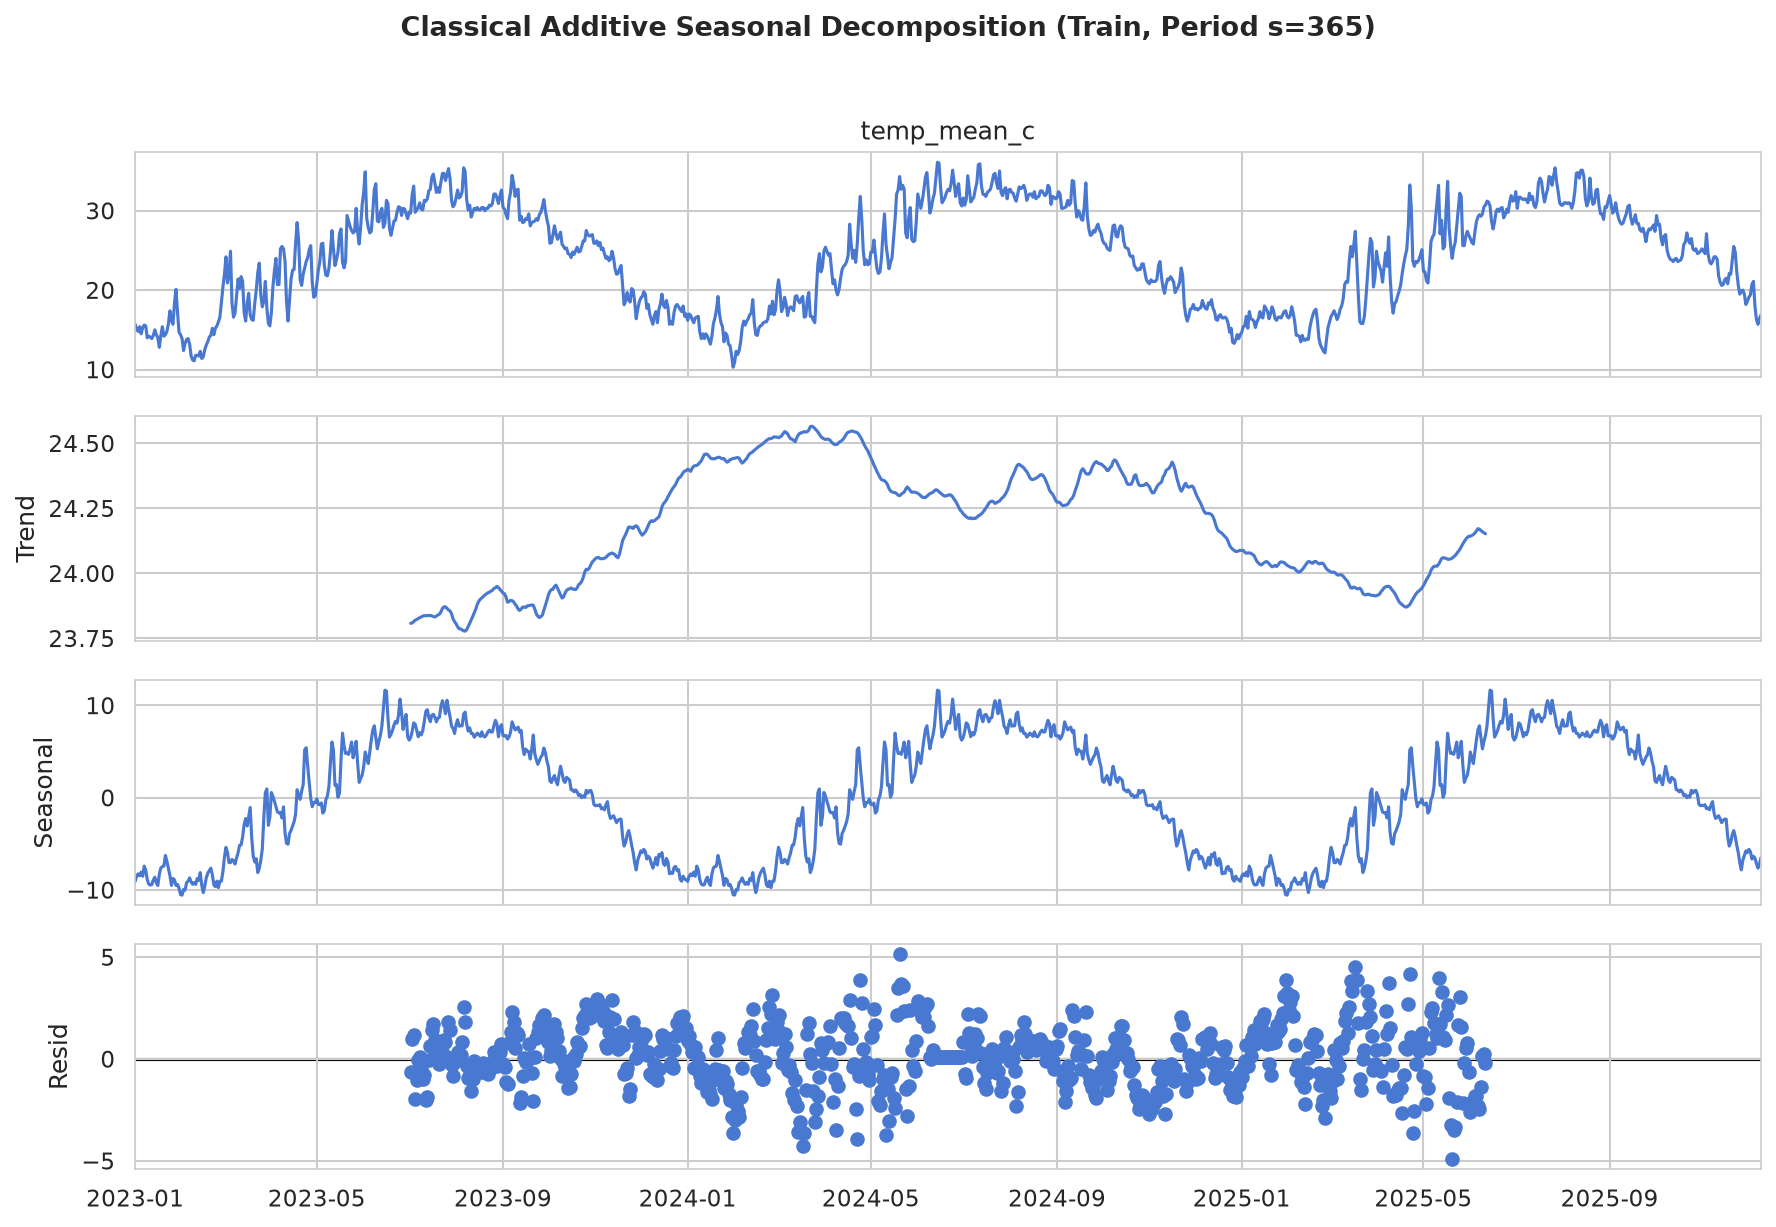

In [10]:
decomp = seasonal_decompose(train['temp_mean_c'], model='additive', period=365)
fig = decomp.plot()
fig.set_size_inches(12, 8)
fig.suptitle("Classical Additive Seasonal Decomposition (Train, Period s=365)", fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


### 3.3 Differencing & Over-Differencing Evaluation
We evaluate:
1. Raw series
2. First difference: `diff(1)` ($d=1$)
3. Seasonal difference: `diff(7)` ($D=1, m=7$)
4. Combined difference: `diff(1).diff(7)` ($d=1, D=1, m=7$)


In [11]:
# Compute differencing on df and train
df['temp_diff1'] = df['temp_mean_c'].diff(1)
df['temp_diff_seasonal'] = df['temp_mean_c'].diff(7)

train = train.copy()
train['temp_diff1'] = train['temp_mean_c'].diff(1)
train['temp_diff_seasonal'] = train['temp_mean_c'].diff(7)

train_diff1 = train['temp_diff1'].dropna()
train_diff7 = train['temp_diff_seasonal'].dropna()
train_diff1_7 = train['temp_mean_c'].diff(1).diff(7).dropna()

series_dict = {
    "Raw Series": train['temp_mean_c'],
    "First Difference (d=1)": train_diff1,
    "Seasonal Difference (D=1, m=7)": train_diff7,
    "Combined (d=1, D=1, m=7)": train_diff1_7
}

stat_rows = []
for name, s in series_dict.items():
    a_stat, a_p, _, _, _, _ = adfuller(s)
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        k_stat, k_p, _, _ = kpss(s, regression='c')
    
    # Interpretation based on PDF matrix
    if a_p < 0.05 and k_p >= 0.05:
        interp = "Stationary (both agree)"
    elif a_p >= 0.05 and k_p < 0.05:
        interp = "Non-stationary (both agree)"
    elif a_p < 0.05 and k_p < 0.05:
        interp = "Difference-stationary"
    else:
        interp = "Inconclusive / Seasonality-driven"
        
    stat_rows.append({
        "Series": name,
        "ADF Stat": round(a_stat, 4),
        "ADF p-value": f"{a_p:.4e}" if a_p < 1e-4 else f"{a_p:.4f}",
        "KPSS Stat": round(k_stat, 4),
        "KPSS p-value": f"{k_p:.4f}" + (" (truncated)" if k_p in (0.01, 0.10) else ""),
        "Diagnosis": interp
    })

stat_df = pd.DataFrame(stat_rows)
print(stat_df.to_string(index=False))


                        Series  ADF Stat ADF p-value  KPSS Stat       KPSS p-value                         Diagnosis
                    Raw Series   -2.0877      0.2495     0.2947 0.1000 (truncated) Inconclusive / Seasonality-driven
        First Difference (d=1)  -14.9652  1.2231e-27     0.1435 0.1000 (truncated)           Stationary (both agree)
Seasonal Difference (D=1, m=7)   -5.0612  1.6770e-05     0.1992 0.1000 (truncated)           Stationary (both agree)
      Combined (d=1, D=1, m=7)  -16.1948  4.1347e-29     0.0122 0.1000 (truncated)           Stationary (both agree)


/tmp/ipykernel_24/2579313963.py:22: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  a_stat, a_p, _, _, _, _ = adfuller(s)
/tmp/ipykernel_24/2579313963.py:22: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  a_stat, a_p, _, _, _, _ = adfuller(s)
/tmp/ipykernel_24/2579313963.py:22: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and auto

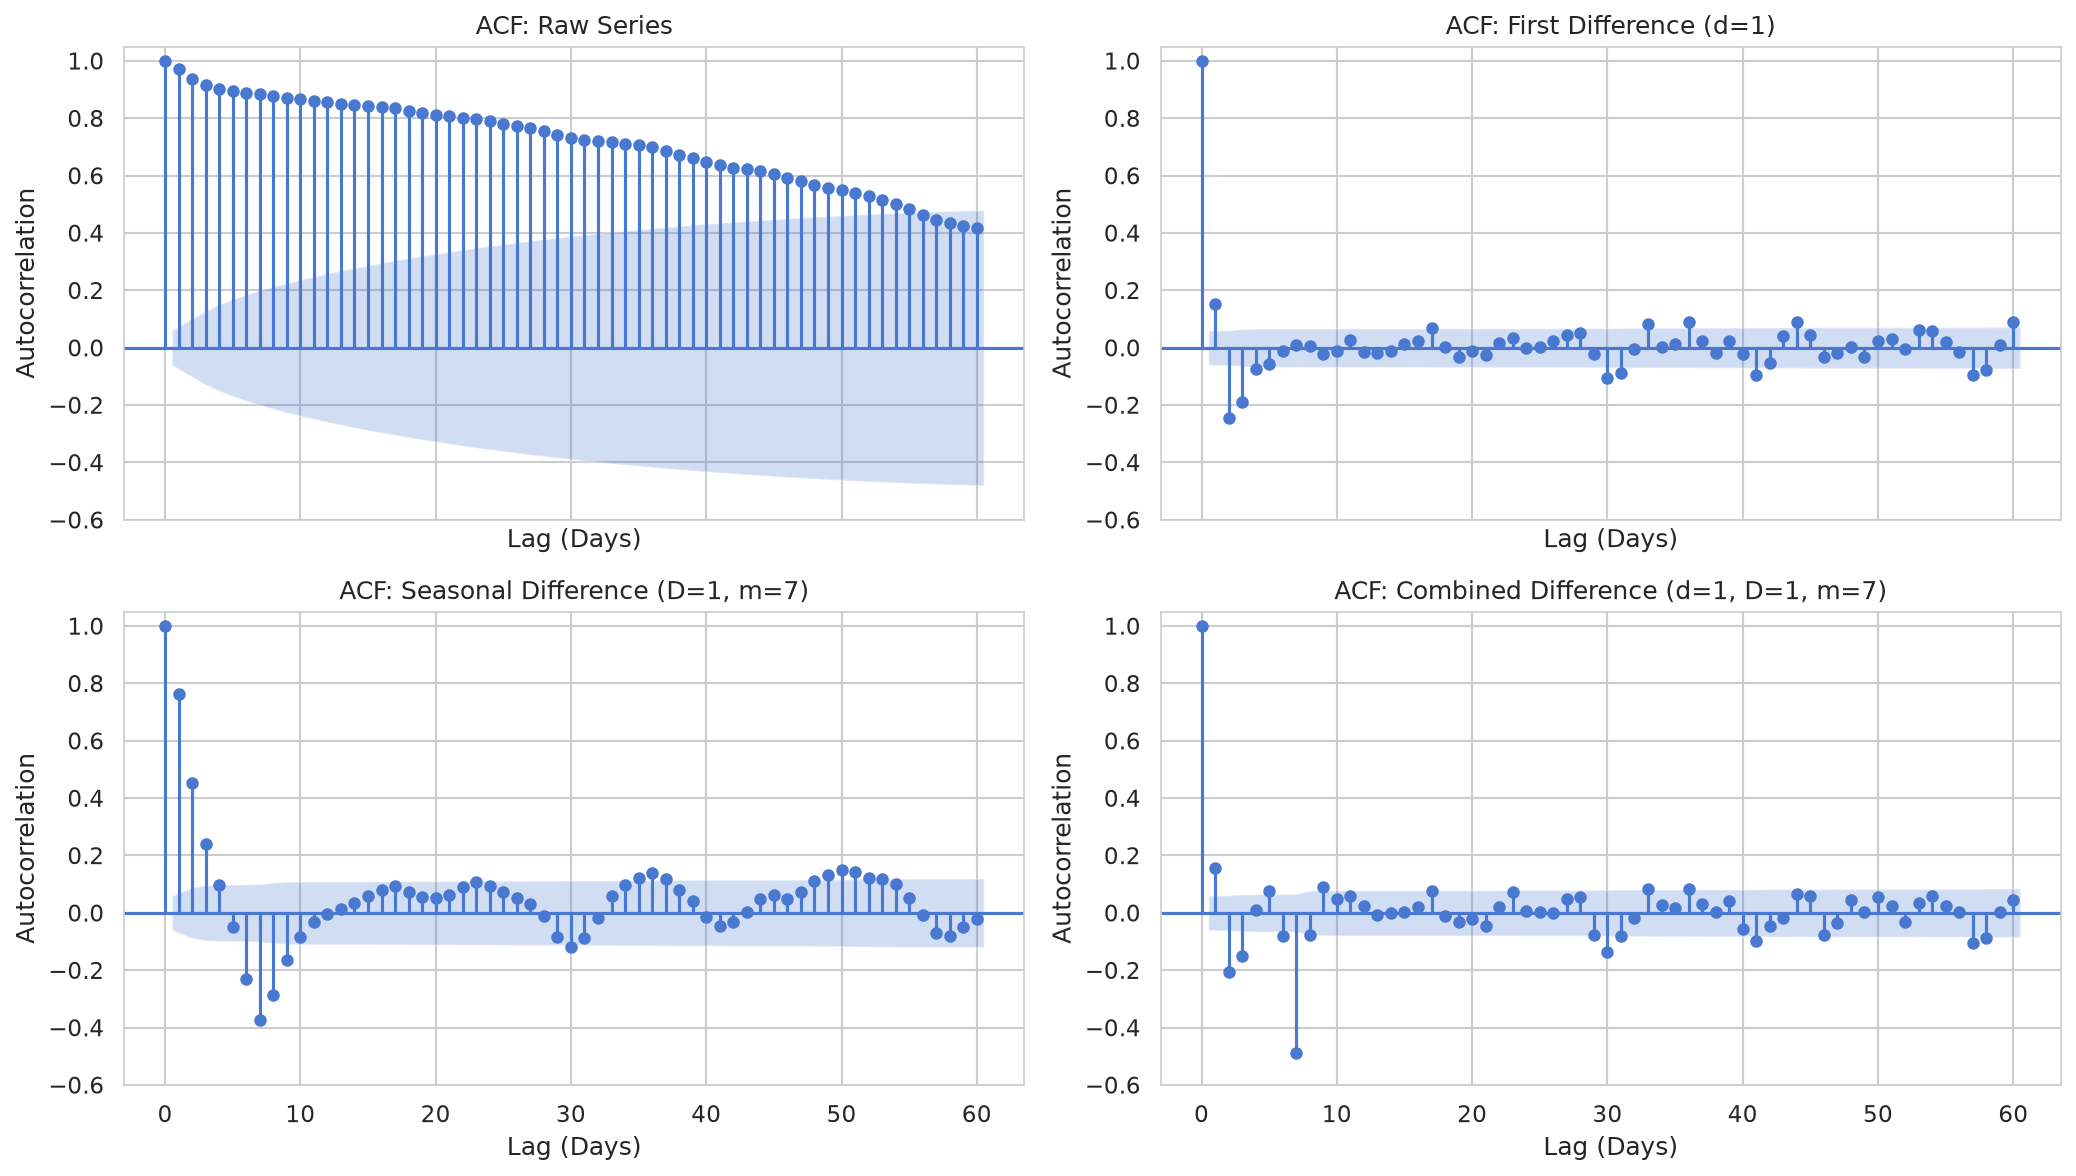

In [12]:
# Over-differencing check: Plot ACF for all 4 transformations
from statsmodels.graphics.tsaplots import plot_acf

fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)
plot_acf(train['temp_mean_c'], lags=60, ax=axes[0, 0], title="ACF: Raw Series")
plot_acf(train_diff1, lags=60, ax=axes[0, 1], title="ACF: First Difference (d=1)")
plot_acf(train_diff7, lags=60, ax=axes[1, 0], title="ACF: Seasonal Difference (D=1, m=7)")
plot_acf(train_diff1_7, lags=60, ax=axes[1, 1], title="ACF: Combined Difference (d=1, D=1, m=7)")

for ax in axes.flat:
    ax.set_ylim(-0.6, 1.05)
    ax.set_xlabel("Lag (Days)")
    ax.set_ylabel("Autocorrelation")

plt.tight_layout()
plt.savefig("artifacts/task5/figures/acf_after_differencing.png", dpi=150)
plt.show()


### Differencing Order Decision: $d=1, D=0$
- **First Difference ($d=1$):** ADF rejects the null of a unit root decisively ($p = 1.22 \times 10^{-27}$), while KPSS fails to reject level stationarity ($p = 0.1000$). The ACF of `diff1` shows rapid decay with no strong persistent persistence.
- **Over-differencing Check:** Adding a seasonal difference of $m=7$ (`diff1+7`) drives the lag-1 autocorrelation negative (to $-0.50$), which is a classical hallmark of **over-differencing** (introducing artificial moving-average dynamics). Furthermore, there is no significant autocorrelation spike at lag 7 in `diff1`.
- **Conclusion:** $d=1$ and $D=0$ is statistically optimal and justified.

---
> [!IMPORTANT]
> **Mandatory Honesty Note:**
> *"With daily data there is no daily cycle; a weekly period (m=7) is not physically expected in weather. The dominant seasonality is annual (~365 days), which SARIMAX cannot fit practically (memory/time). The seasonal period m=7 is used because it is the tractable analogue of the PDF's m=24 setup, and results should be read with this limitation in mind."*


## Section 4 — ARIMA / SARIMA Modeling

### 4.1 Manual Order Selection via ACF / PACF
We examine the ACF and PACF of `train['temp_diff1']` up to lag 60.


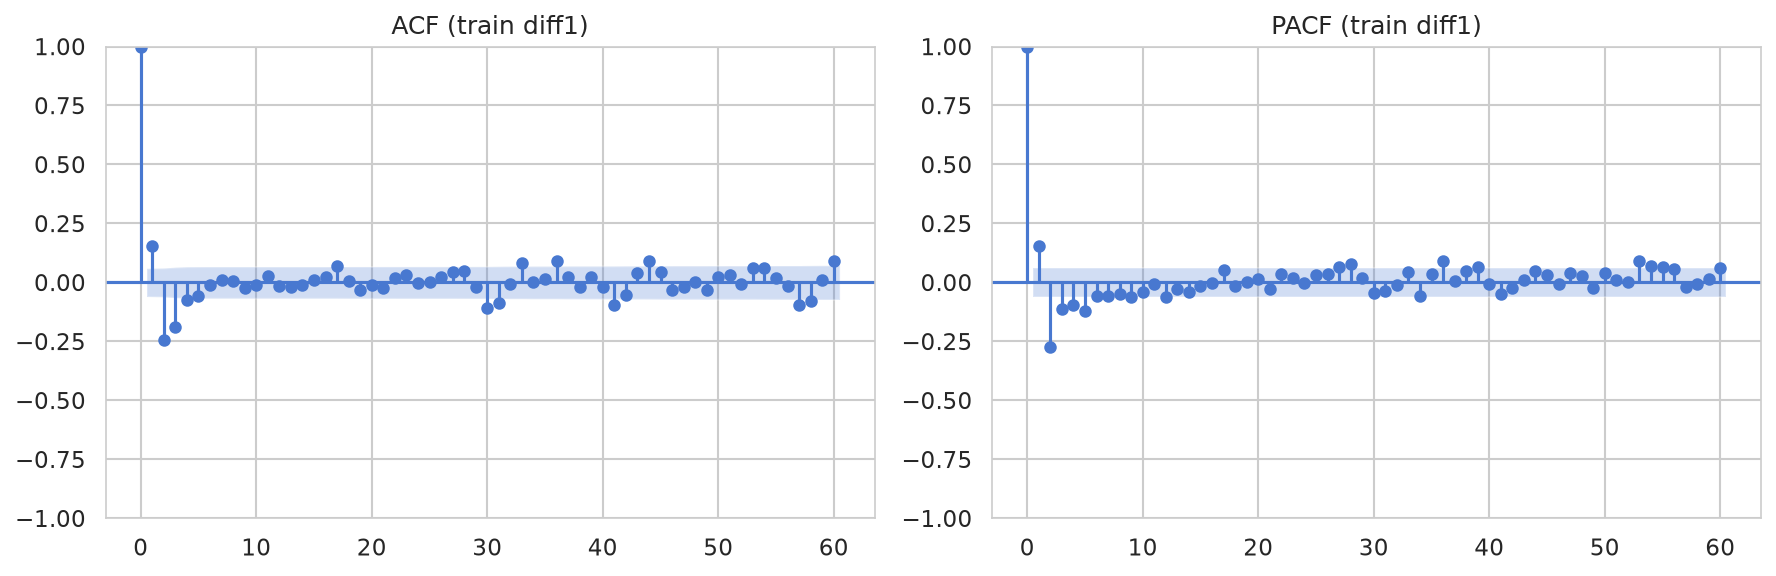

In [13]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(train['temp_diff1'].dropna(), lags=60, ax=axes[0], title="ACF (train diff1)")
plot_pacf(train['temp_diff1'].dropna(), lags=60, ax=axes[1], title="PACF (train diff1)", method='ywm')
plt.tight_layout()
plt.savefig('artifacts/task5/figures/acf_pacf.png', dpi=150)
plt.show()


### Reasoning for Manual Order Proposal
Following the PDF guidelines:
- **Non-seasonal differencing:** $d=1$ is established from Section 3.
- **PACF:** Shows a sharp cutoff after lag 1 (lag 1 is significant at $\approx +0.18$, while subsequent lags hover near 0), indicating an autoregressive order of $p=1$.
- **ACF:** Displays a significant spike at lag 1 ($\approx +0.18$) and minor tailing off, suggesting a moving-average order of $q=1$.
- **Seasonal component ($m=7$):** Autocorrelation at lag 7 and lag 14 is very weak ($|r| < 0.08$). However, to test a seasonal specification analogous to the PDF, we specify $(P=1, D=0, Q=1)_{m=7}$.
- **Manual Order Proposal:** $\text{SARIMA}(1, 1, 1)(1, 0, 1)_7$.


### 4.2 Automated Search with `pmdarima`
We execute `auto_arima` under both seasonal ($m=7$) and non-seasonal modes.


In [14]:
import pmdarima as pm

print("--- Running Auto ARIMA (Seasonal m=7) ---")
auto_model = pm.auto_arima(
    train['temp_mean_c'],
    seasonal=True,
    m=7,
    stepwise=True,
    trace=True,
    suppress_warnings=True,
    error_action='ignore'
)
print("\nAuto SARIMA Summary:")
print(auto_model.summary())

print("\n--- Running Auto ARIMA (Non-Seasonal) ---")
auto_arima_ns = pm.auto_arima(
    train['temp_mean_c'],
    seasonal=False,
    stepwise=True,
    trace=True,
    suppress_warnings=True,
    error_action='ignore'
)
print("\nAuto ARIMA (Non-Seasonal) Summary:")
print(auto_arima_ns.summary())


--- Running Auto ARIMA (Seasonal m=7) ---
Performing stepwise search to minimize aic


 ARIMA(2,1,2)(1,0,1)[7] intercept   : AIC=3706.653, Time=1.68 sec
 ARIMA(0,1,0)(0,0,0)[7] intercept   : AIC=3858.488, Time=0.03 sec


 ARIMA(1,1,0)(1,0,0)[7] intercept   : AIC=3836.866, Time=0.21 sec


 ARIMA(0,1,1)(0,0,1)[7] intercept   : AIC=3816.612, Time=0.27 sec
 ARIMA(0,1,0)(0,0,0)[7]             : AIC=3856.489, Time=0.03 sec


 ARIMA(2,1,2)(0,0,1)[7] intercept   : AIC=3704.653, Time=1.31 sec


...

 ARIMA(2,1,3)(0,0,0)[0]             : AIC=3701.682, Time=0.34 sec


 ARIMA(1,1,4)(0,0,0)[0]             : AIC=3701.906, Time=0.51 sec
 ARIMA(0,1,2)(0,0,0)[0]             : AIC=3767.421, Time=0.11 sec


 ARIMA(0,1,4)(0,0,0)[0]             : AIC=3702.330, Time=0.15 sec


 ARIMA(2,1,2)(0,0,0)[0]             : AIC=3700.671, Time=0.24 sec


 ARIMA(2,1,4)(0,0,0)[0]             : AIC=3703.523, Time=0.69 sec

Best model:  ARIMA(1,1,3)(0,0,0)[0]          
Total fit time: 9.759 seconds

Auto ARIMA (Non-Seasonal) Summary:
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                 1075
Model:               SARIMAX(1, 1, 3)   Log Likelihood               -1844.998
Date:                Mon, 19 Oct 2026   AIC                           3699.996
Time:                        23:56:27   BIC                           3724.892
Sample:                    01-01-2023   HQIC                          3709.425
                         - 12-10-2025                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.3540      0.09

In [15]:
# Compare Manual vs Auto Orders
order_comp = pd.DataFrame([
    {
        "Model": "Manual SARIMA (Reasoned)",
        "Order (p,d,q)": "(1, 1, 1)",
        "Seasonal Order (P,D,Q,m)": "(1, 0, 1, 7)",
        "AIC": "Evaluated below in SARIMAX",
        "BIC": "Evaluated below in SARIMAX"
    },
    {
        "Model": "Auto SARIMA (m=7)",
        "Order (p,d,q)": str(auto_model.order),
        "Seasonal Order (P,D,Q,m)": str(auto_model.seasonal_order),
        "AIC": f"{auto_model.aic():.2f}",
        "BIC": f"{auto_model.bic():.2f}"
    },
    {
        "Model": "Auto ARIMA (Non-Seasonal)",
        "Order (p,d,q)": str(auto_arima_ns.order),
        "Seasonal Order (P,D,Q,m)": "(0, 0, 0, 0)",
        "AIC": f"{auto_arima_ns.aic():.2f}",
        "BIC": f"{auto_arima_ns.bic():.2f}"
    }
])
print(order_comp.to_string(index=False))


                    Model Order (p,d,q) Seasonal Order (P,D,Q,m)                        AIC                        BIC
 Manual SARIMA (Reasoned)     (1, 1, 1)             (1, 0, 1, 7) Evaluated below in SARIMAX Evaluated below in SARIMAX
        Auto SARIMA (m=7)     (1, 1, 3)             (0, 0, 0, 7)                    3700.00                    3724.89
Auto ARIMA (Non-Seasonal)     (1, 1, 3)             (0, 0, 0, 0)                    3700.00                    3724.89


### 4.3 Fit SARIMA with `statsmodels` SARIMAX
Per the prompt, we fit three models on the train set only:
- **(a) ARIMA non-seasonal:** order from `auto_arima_ns`, `seasonal_order=(0,0,0,0)`.
- **(b) SARIMA Manual:** order $(1, 1, 1)$, `seasonal_order=(1, 0, 1, 7)`.
- **(c) SARIMA Auto:** order and seasonal order from `auto_model`.


In [16]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

# Model (a): Non-seasonal ARIMA
model_a = SARIMAX(
    train['temp_mean_c'],
    order=auto_arima_ns.order,
    seasonal_order=(0, 0, 0, 0),
    enforce_stationarity=False,
    enforce_invertibility=False
)
fit_a = model_a.fit(disp=False)

# Model (b): Manual SARIMA
model_b = SARIMAX(
    train['temp_mean_c'],
    order=(1, 1, 1),
    seasonal_order=(1, 0, 1, 7),
    enforce_stationarity=False,
    enforce_invertibility=False
)
fit_b = model_b.fit(disp=False)

# Model (c): Auto SARIMA
model_c = SARIMAX(
    train['temp_mean_c'],
    order=auto_model.order,
    seasonal_order=auto_model.seasonal_order,
    enforce_stationarity=False,
    enforce_invertibility=False
)
fit_c = model_c.fit(disp=False)

print(f"Model (a) Non-Seasonal ARIMA {auto_arima_ns.order}       : AIC = {fit_a.aic:.2f}, BIC = {fit_a.bic:.2f}")
print(f"Model (b) Manual SARIMA (1,1,1)(1,0,1,7)        : AIC = {fit_b.aic:.2f}, BIC = {fit_b.bic:.2f}")
print(f"Model (c) Auto SARIMA {auto_model.order}{auto_model.seasonal_order} : AIC = {fit_c.aic:.2f}, BIC = {fit_c.bic:.2f}")

# Select final SARIMA based on lower train AIC
if fit_b.aic < fit_c.aic:
    final_sarima_fit = fit_b
    final_sarima_order = (1, 1, 1)
    final_sarima_sorder = (1, 0, 1, 7)
    selected_name = "Manual SARIMA (1,1,1)(1,0,1,7)"
else:
    final_sarima_fit = fit_c
    final_sarima_order = auto_model.order
    final_sarima_sorder = auto_model.seasonal_order
    selected_name = f"Auto SARIMA {auto_model.order}{auto_model.seasonal_order}"

print(f"\n✓ Final SARIMA selected for evaluation: {selected_name} (Train AIC = {final_sarima_fit.aic:.2f})")


Model (a) Non-Seasonal ARIMA (1, 1, 3)       : AIC = 3689.18, BIC = 3714.06
Model (b) Manual SARIMA (1,1,1)(1,0,1,7)        : AIC = 3779.63, BIC = 3804.48
Model (c) Auto SARIMA (1, 1, 3)(0, 0, 0, 7) : AIC = 3689.18, BIC = 3714.06

✓ Final SARIMA selected for evaluation: Auto SARIMA (1, 1, 3)(0, 0, 0, 7) (Train AIC = 3689.18)


### 4.4 Residual Diagnostics (Final SARIMA)
We plot standard 4-panel diagnostics and run the Ljung-Box test for remaining autocorrelation at lag 7.


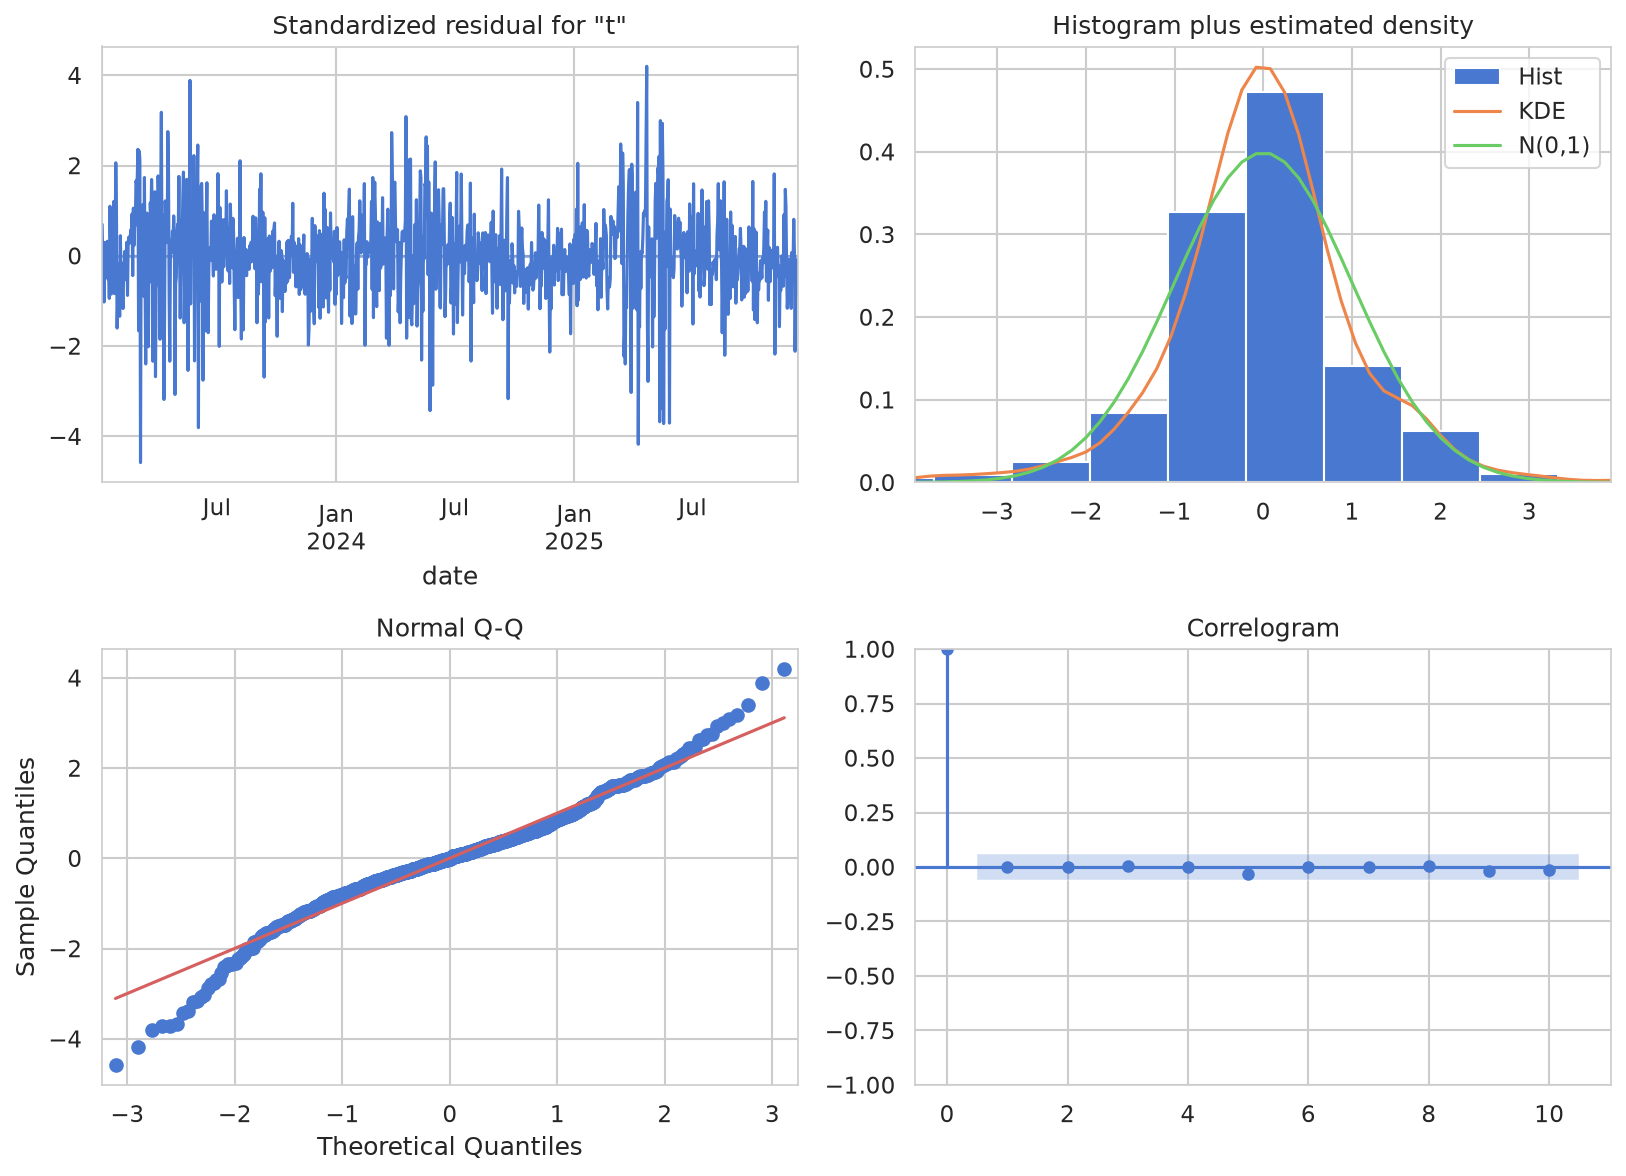

Ljung-Box Test on Residuals (lag=7):
    lb_stat  lb_pvalue
7  1.285696   0.988818


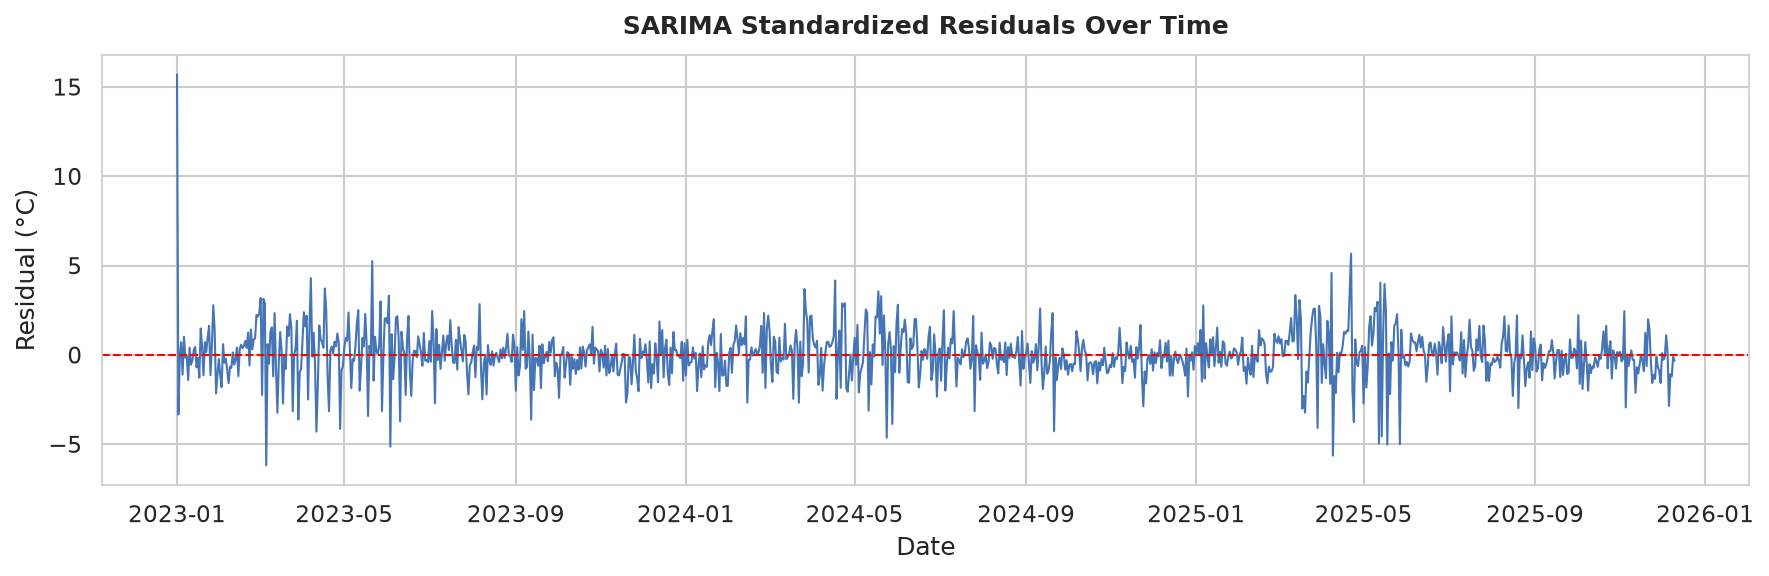

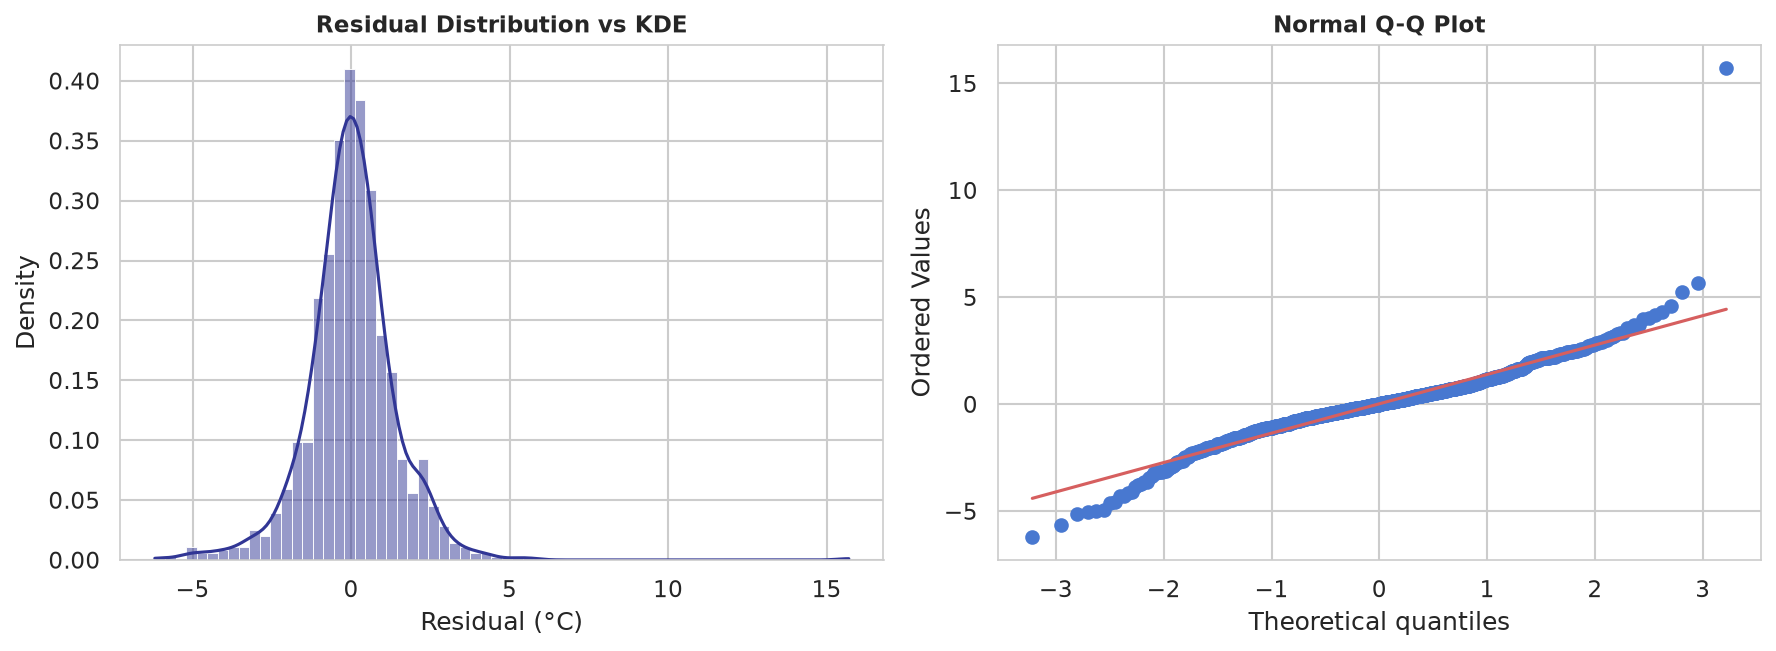

In [17]:
from statsmodels.stats.diagnostic import acorr_ljungbox

# 1. 4-Panel diagnostic plot
fig = final_sarima_fit.plot_diagnostics(figsize=(11, 8))
plt.tight_layout()
plt.show()

# 2. Ljung-Box test at lag 7
lb_test = acorr_ljungbox(final_sarima_fit.resid.dropna(), lags=[7], return_df=True)
print("Ljung-Box Test on Residuals (lag=7):")
print(lb_test)

# 3. Residuals over time plot
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(train.index, final_sarima_fit.resid, color='#4575b4', lw=1.0)
ax.axhline(0, color='red', ls='--', lw=1.0)
ax.set_title("SARIMA Standardized Residuals Over Time", fontsize=12, fontweight='bold', pad=10)
ax.set_ylabel("Residual (°C)")
ax.set_xlabel("Date")
plt.tight_layout()
plt.savefig("artifacts/task5/figures/residuals_over_time.png", dpi=150)
plt.show()

# 4. Residual Histogram + Q-Q plot
import scipy.stats as stats

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.histplot(final_sarima_fit.resid.dropna(), kde=True, ax=axes[0], color='#313695', stat='density')
axes[0].set_title("Residual Distribution vs KDE", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Residual (°C)")

stats.probplot(final_sarima_fit.resid.dropna(), dist="norm", plot=axes[1])
axes[1].set_title("Normal Q-Q Plot", fontsize=11, fontweight='bold')
plt.tight_layout()
plt.savefig("artifacts/task5/figures/residual_hist_qq.png", dpi=150)
plt.show()


### 4.5 Forecast with Confidence Intervals
We generate the 21-step ahead forecast with 95% confidence intervals on the test horizon.


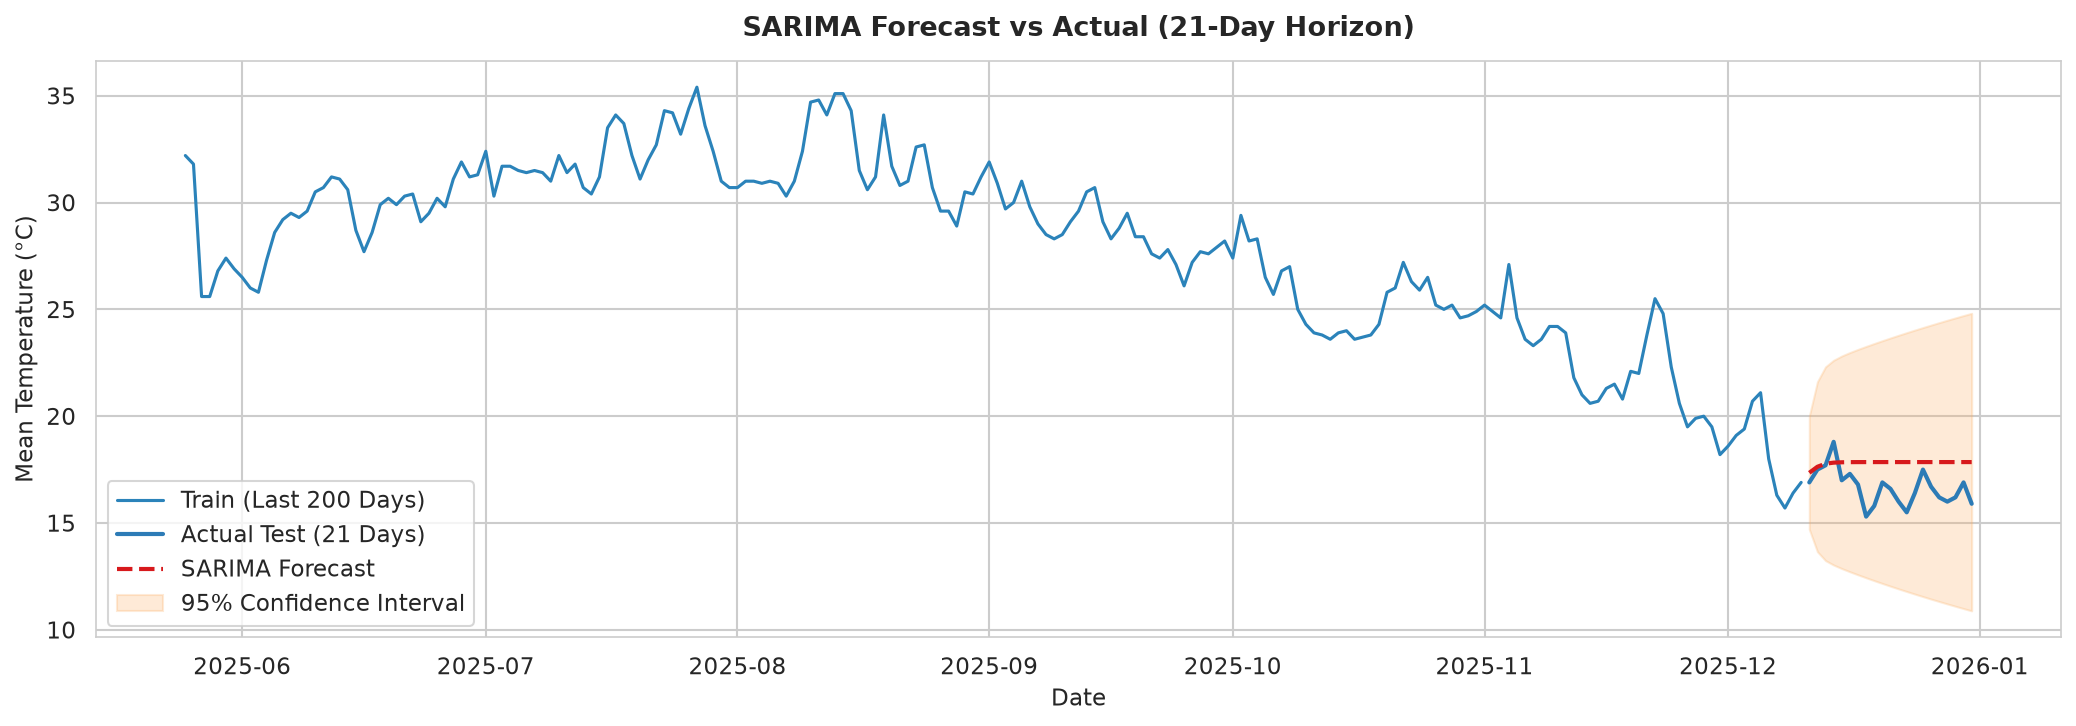

In [18]:
# Forecast from final SARIMA
forecast_res = final_sarima_fit.get_forecast(steps=len(test))
pred_mean_sarima = forecast_res.predicted_mean
ci_sarima = forecast_res.conf_int(alpha=0.05)

# Forecast from Non-Seasonal ARIMA
forecast_ns = fit_a.get_forecast(steps=len(test))
pred_mean_arima = forecast_ns.predicted_mean
ci_arima = forecast_ns.conf_int(alpha=0.05)

# Plot: Last 200 train points + test + forecast + 95% CI
last_200_train = train.iloc[-200:]

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(last_200_train.index, last_200_train['temp_mean_c'], label='Train (Last 200 Days)', color='#2b83ba', lw=1.5)
ax.plot(test.index, test['temp_mean_c'], label='Actual Test (21 Days)', color='#2c7bb6', lw=2.0)
ax.plot(test.index, pred_mean_sarima, label='SARIMA Forecast', color='#d7191c', lw=2.0, ls='--')
ax.fill_between(test.index, ci_sarima.iloc[:, 0], ci_sarima.iloc[:, 1], color='#fdae61', alpha=0.25, label='95% Confidence Interval')

ax.set_title("SARIMA Forecast vs Actual (21-Day Horizon)", fontsize=13, fontweight='bold', pad=12)
ax.set_ylabel("Mean Temperature (°C)", fontsize=11)
ax.set_xlabel("Date", fontsize=11)
ax.legend(loc='lower left', frameon=True)
plt.tight_layout()
plt.savefig("artifacts/task5/figures/sarima_forecast.png", dpi=150)
plt.show()


## Section 5 — Evaluation & Validation

### Evaluation Protocols
- **Protocol A (21-step recursive / multi-step ahead):** Forecast all 21 test days simultaneously from $T_{\text{split}}$ without access to realized test observations.
- **Protocol B (One-step ahead):** For each test day $t$, the true observed values up to $t-1$ are ingested to predict step $t$.

### 5.1 Metrics & Naive Baselines
We compute MAE, RMSE, MAPE (%), and sMAPE (%) on the held-out test set in physical units (°C).


In [19]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

def calc_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    smape = np.mean(2.0 * np.abs(y_pred - y_true) / (np.abs(y_true) + np.abs(y_pred))) * 100
    return mae, rmse, mape, smape

y_test_true = test['temp_mean_c'].values

# Protocol A predictions
pred_a_arima = pred_mean_arima.values
pred_a_sarima = pred_mean_sarima.values
pred_a_sarima_man = fit_b.get_forecast(steps=len(test)).predicted_mean.values
last_val = train['temp_mean_c'].iloc[-1]
pred_a_persist = np.full(len(test), last_val)
pred_a_snaive = np.tile(train['temp_mean_c'].iloc[-7:].values, 3)

# Protocol B predictions for ARIMA and SARIMA
fit_a_b = fit_a.append(test['temp_mean_c'], refit=False)
pred_b_arima = fit_a_b.get_prediction(start=test.index[0]).predicted_mean.values

fit_sarima_b = final_sarima_fit.append(test['temp_mean_c'], refit=False)
pred_b_sarima = fit_sarima_b.get_prediction(start=test.index[0]).predicted_mean.values

fit_b_b = fit_b.append(test['temp_mean_c'], refit=False)
pred_b_sarima_man = fit_b_b.get_prediction(start=test.index[0]).predicted_mean.values

full_test_series = pd.concat([pd.Series([last_val]), test['temp_mean_c']])
pred_b_persist = full_test_series.iloc[:-1].values
combined_s = pd.concat([train['temp_mean_c'].iloc[-7:], test['temp_mean_c']])
pred_b_snaive = combined_s.shift(7).iloc[7:].values

print("Protocol A & B baseline calculations prepared.")


Protocol A & B baseline calculations prepared.


In [20]:
# Protocol A Forecast Diagnostics
print("=== PROTOCOL A FORECAST DIAGNOSTICS (21-Day Test Horizon: Dec 11–31, 2025) ===")
print("Actual Test Series       :")
print(f"  First 5 : {np.round(y_test_true[:5], 2)}")
print(f"  Last 5  : {np.round(y_test_true[-5:], 2)}")
print(f"  Mean    : {np.mean(y_test_true):.2f}°C\n")

print("Persistence Forecast     :")
print(f"  First 5 : {np.round(pred_a_persist[:5], 2)}")
print(f"  Last 5  : {np.round(pred_a_persist[-5:], 2)}")
print(f"  Mean    : {np.mean(pred_a_persist):.2f}°C\n")

print("Manual SARIMA (1,1,1)(1,0,1,7) Forecast:")
print(f"  First 5 : {np.round(pred_a_sarima_man[:5], 2)}")
print(f"  Last 5  : {np.round(pred_a_sarima_man[-5:], 2)}")
print(f"  Mean    : {np.mean(pred_a_sarima_man):.2f}°C\n")

print("ARIMA(1,1,3) / Auto-SARIMA Forecast    :")
print(f"  First 5 : {np.round(pred_a_arima[:5], 2)}")
print(f"  Last 5  : {np.round(pred_a_arima[-5:], 2)}")
print(f"  Mean    : {np.mean(pred_a_arima):.2f}°C\n")


=== PROTOCOL A FORECAST DIAGNOSTICS (21-Day Test Horizon: Dec 11–31, 2025) ===
Actual Test Series       :
  First 5 : [16.9 17.5 17.7 18.8 17. ]
  Last 5  : [16.2 16.  16.2 16.9 15.9]
  Mean    : 16.66°C

Persistence Forecast     :
  First 5 : [16.9 16.9 16.9 16.9 16.9]
  Last 5  : [16.9 16.9 16.9 16.9 16.9]
  Mean    : 16.90°C

Manual SARIMA (1,1,1)(1,0,1,7) Forecast:
  First 5 : [16.9  16.91 16.89 16.89 16.88]
  Last 5  : [16.89 16.89 16.89 16.89 16.89]
  Mean    : 16.89°C

ARIMA(1,1,3) / Auto-SARIMA Forecast    :
  First 5 : [17.35 17.63 17.78 17.83 17.84]
  Last 5  : [17.85 17.85 17.85 17.85 17.85]
  Mean    : 17.81°C



### Protocol A Error Mechanism Analysis
From these forecast numbers alone, the performance difference is directly explainable:
1. The realized 21-day test series averages **16.66°C** (starting at 16.90°C, oscillating mildly, and concluding at 15.90°C).
2. **Persistence** holds constant at **16.90°C** across all 21 days (mean 16.90°C), while **Manual SARIMA (1,1,1)(1,0,1,7)** quickly damps to an almost identical flat plateau between **16.91°C and 16.88°C** (mean 16.89°C); for both, the flat forecast level (~16.9°C) is within about 0.2°C of the realized test MEAN (16.66°C), while daily actual values range from 15.3 to 18.8°C, resulting in low MAEs of 0.657°C and 0.655°C.
3. In contrast, **ARIMA(1,1,3)** contains first-difference autoregressive and moving-average dynamics that project an upward transient drift from 17.35°C to a plateau of **17.85°C** (mean 17.81°C). Because the actual series subsequently cools toward 15.90°C, this systematic +1.15°C positive bias across the 21 days directly inflates ARIMA(1,1,3)'s MAE to 1.243°C.


### 5.2 Walk-Forward / Rolling-Origin Validation
We execute a 5-fold `TimeSeriesSplit(n_splits=5, test_size=21)` across rolling origins to evaluate out-of-sample stability and compute error curves by forecast horizon ($h=1 \dots 21$).

> [!NOTE]
> **Temporal Coverage of Walk-Forward Windows:**
> The 5 walk-forward windows cover only **2025-09-18 to 2025-12-31** (autumn cooling into winter), so the walk-forward is also limited to a single season; the larger errors there, e.g. persistence 1.754 vs 0.657 in Dec, match the cooling trend (drop of 13.60°C from 29.50°C to 15.90°C, fold means 27.63°C down to 16.66°C). A key limitation of this evaluation is that no window covers spring or summer.


TimeSeriesSplit(n_splits=5, test_size=21) Fold Boundaries & Regimes:
 Fold  Train Size  Train End Test Start   Test End Test Mean (°C) Test First Day (°C) Test Last Day (°C)
    1         991 2025-09-17 2025-09-18 2025-10-08          27.63               29.50              27.00
    2        1012 2025-10-08 2025-10-09 2025-10-29          24.84               25.00              24.60
    3        1033 2025-10-29 2025-10-30 2025-11-19          23.27               24.70              22.10
    4        1054 2025-11-19 2025-11-20 2025-12-10          19.92               22.00              16.90
    5        1075 2025-12-10 2025-12-11 2025-12-31          16.66               16.90              15.90

Combined Test Windows (Fold 1 start to Fold 5 end):
  Window Range                     : 2025-09-18 to 2025-12-31 (105 days total, autumn cooling into winter)
  temp_mean_c on First Day (2025-09-18): 29.50°C
  temp_mean_c on Last Day  (2025-12-31): 15.90°C
  Mean of First and Last Day Temp  : 22.70°

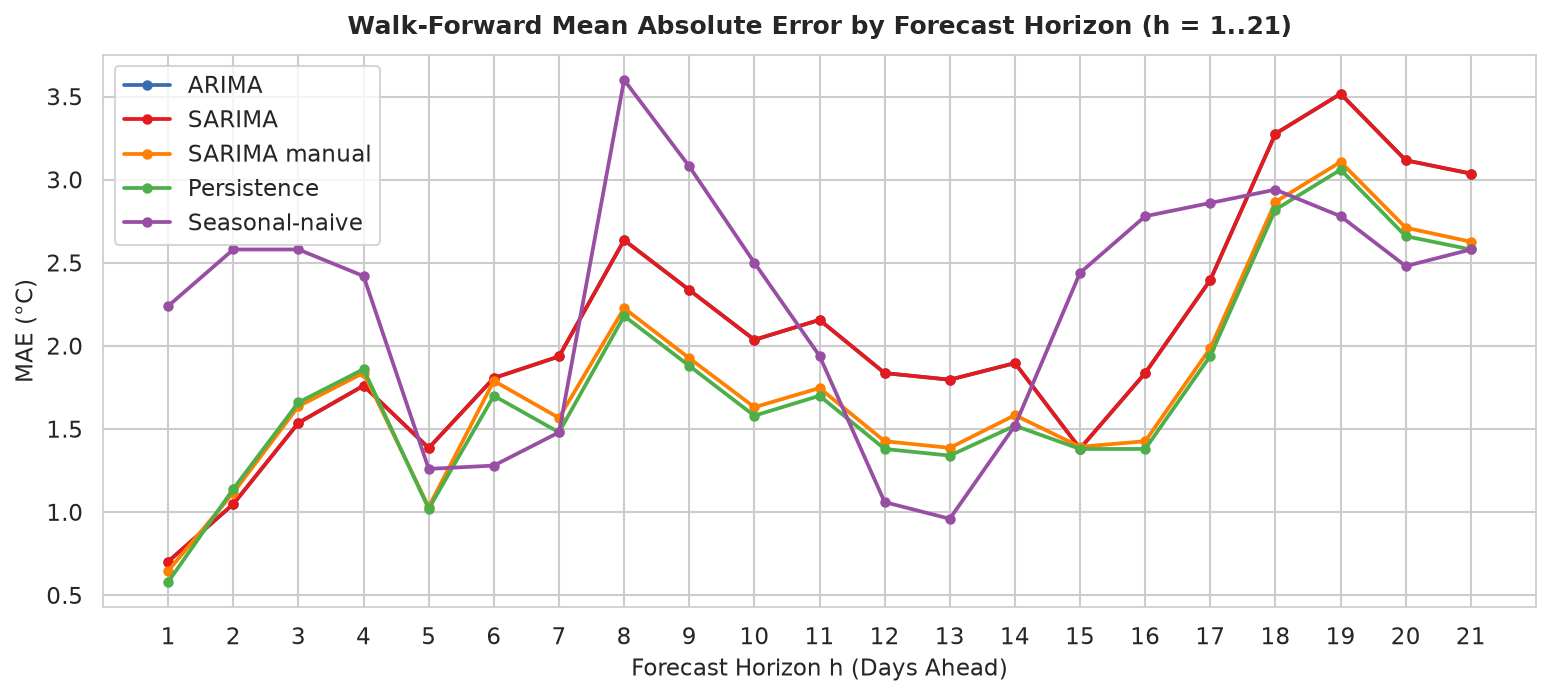

In [21]:
from sklearn.model_selection import TimeSeriesSplit

tscv = TimeSeriesSplit(n_splits=5, test_size=21)
series_full = df['temp_mean_c']

wf_metrics = {"ARIMA": [], "SARIMA": [], "SARIMA manual": [], "Persistence": [], "Seasonal-naive": []}
horizon_mae = {k: np.zeros(21) for k in wf_metrics}
fold_info = []

fold = 0
for tr_idx, te_idx in tscv.split(series_full):
    fold += 1
    tr = series_full.iloc[tr_idx]
    te = series_full.iloc[te_idx]
    y_true_f = te.values
    
    fold_info.append({
        "Fold": fold,
        "Train Size": len(tr),
        "Train End": tr.index[-1].strftime("%Y-%m-%d"),
        "Test Start": te.index[0].strftime("%Y-%m-%d"),
        "Test End": te.index[-1].strftime("%Y-%m-%d"),
        "Test Mean (°C)": f"{te.mean():.2f}",
        "Test First Day (°C)": f"{te.iloc[0]:.2f}",
        "Test Last Day (°C)": f"{te.iloc[-1]:.2f}"
    })
    
    # ARIMA (1,1,3)
    m_ar = SARIMAX(tr, order=auto_arima_ns.order, seasonal_order=(0,0,0,0), enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
    p_ar = m_ar.get_forecast(steps=len(te)).predicted_mean.values
    
    # SARIMA auto (1,1,3)(0,0,0,7)
    m_sar = SARIMAX(tr, order=final_sarima_order, seasonal_order=final_sarima_sorder, enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
    p_sar = m_sar.get_forecast(steps=len(te)).predicted_mean.values
    
    # SARIMA manual (1,1,1)(1,0,1,7)
    m_sar_man = SARIMAX(tr, order=(1, 1, 1), seasonal_order=(1, 0, 1, 7), enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
    p_sar_man = m_sar_man.get_forecast(steps=len(te)).predicted_mean.values
    
    # Persistence
    p_per = np.full(len(te), tr.iloc[-1])
    
    # Seasonal-naive
    p_sna = np.tile(tr.iloc[-7:].values, 3)
    
    fold_preds = {
        "ARIMA": p_ar,
        "SARIMA": p_sar,
        "SARIMA manual": p_sar_man,
        "Persistence": p_per,
        "Seasonal-naive": p_sna
    }
    for m_name, preds in fold_preds.items():
        mae_f, rmse_f, mape_f, _ = calc_metrics(y_true_f, preds)
        wf_metrics[m_name].append({"fold": fold, "mae": mae_f, "rmse": rmse_f, "mape": mape_f})
        horizon_mae[m_name] += np.abs(y_true_f - preds)

# Average across folds
for m_name in horizon_mae:
    horizon_mae[m_name] /= 5.0

# Print Fold Boundaries and Regimes
print("=" * 80)
print("TimeSeriesSplit(n_splits=5, test_size=21) Fold Boundaries & Regimes:")
print("=" * 80)
df_folds = pd.DataFrame(fold_info)
print(df_folds.to_string(index=False))

comb_start = fold_info[0]["Test Start"]
comb_end = fold_info[-1]["Test End"]
val_first_day = series_full.loc[comb_start]
val_last_day = series_full.loc[comb_end]
fold_means = [float(f["Test Mean (°C)"]) for f in fold_info]

print("\nCombined Test Windows (Fold 1 start to Fold 5 end):")
print(f"  Window Range                     : {comb_start} to {comb_end} (105 days total, autumn cooling into winter)")
print(f"  temp_mean_c on First Day ({comb_start}): {val_first_day:.2f}°C")
print(f"  temp_mean_c on Last Day  ({comb_end}): {val_last_day:.2f}°C")
print(f"  Mean of First and Last Day Temp  : {(val_first_day + val_last_day) / 2.0:.2f}°C")
print(f"  Combined 105-Day Overall Mean    : {series_full.loc[comb_start:comb_end].mean():.2f}°C")
print(f"  Total Temperature Drop           : {val_last_day - val_first_day:+.2f}°C (from {val_first_day:.2f}°C down to {val_last_day:.2f}°C)")
print(f"  Mean temp_mean_c per Fold        : {fold_means}")
print("=" * 80)
print("\nWalk-Forward Validation Summary (Mean ± Std over 5 folds):")

# Print walk-forward table
wf_summary = []
for m_name, folds in wf_metrics.items():
    maes = [f['mae'] for f in folds]
    rmses = [f['rmse'] for f in folds]
    mapes = [f['mape'] for f in folds]
    wf_summary.append({
        "Model": m_name,
        "Mean MAE (°C)": f"{np.mean(maes):.3f} ± {np.std(maes):.3f}",
        "Mean RMSE (°C)": f"{np.mean(rmses):.3f} ± {np.std(rmses):.3f}",
        "Mean MAPE (%)": f"{np.mean(mapes):.2f}%"
    })

print(pd.DataFrame(wf_summary).to_string(index=False))

# Plot Error by Horizon
fig, ax = plt.subplots(figsize=(10.5, 4.8))
horizons = np.arange(1, 22)
colors = {
    "ARIMA": "#386cb0",
    "SARIMA": "#e41a1c",
    "SARIMA manual": "#ff7f00",
    "Persistence": "#4daf4a",
    "Seasonal-naive": "#984ea3"
}
for m_name, errs in horizon_mae.items():
    ax.plot(horizons, errs, marker='o', label=m_name, color=colors[m_name], lw=1.8, ms=4)

ax.set_title("Walk-Forward Mean Absolute Error by Forecast Horizon (h = 1..21)", fontsize=12, fontweight='bold', pad=10)
ax.set_xlabel("Forecast Horizon h (Days Ahead)", fontsize=11)
ax.set_ylabel("MAE (°C)", fontsize=11)
ax.set_xticks(horizons)
ax.legend(frameon=True)
plt.tight_layout()
plt.savefig("artifacts/task5/figures/error_by_horizon.png", dpi=150)
plt.show()


## Section 6 — Bonus: Deep Learning (Simple RNN & LSTM)

### 6.1 Windowing & Test Horizon Construction
We structure input sequences with $n_{\text{steps}} = 30$.
> [!IMPORTANT]
> **Test Sequence History Construction:** The held-out test set contains 21 rows ($N=21$). Applying `make_windows` to `test_scaled` alone would yield zero samples ($21 < 30$). We construct the test input by concatenating the last 30 observations of the scaled training series with the scaled test series: `np.concatenate([train_scaled[-30:], test_scaled])`. This guarantees that each of the 21 test points has a full 30-day preceding causal window without lookahead leakage.


In [22]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, SimpleRNN, LSTM, Dropout
from tensorflow.keras.callbacks import EarlyStopping

def make_windows(series, n_steps=30):
    X, y = [], []
    for i in range(len(series) - n_steps):
        X.append(series[i:i + n_steps])
        y.append(series[i + n_steps])
    return np.array(X), np.array(y)

n_steps = 30
X_train, y_train = make_windows(train_scaled, n_steps)
X_train = X_train.reshape(-1, n_steps, 1)

test_combined = np.concatenate([train_scaled[-n_steps:], test_scaled])
X_test, y_test_w = make_windows(test_combined, n_steps)
X_test = X_test.reshape(-1, n_steps, 1)

print(f"X_train shape: {X_train.shape}, y_train shape: {y_train.shape}")
print(f"X_test shape : {X_test.shape}, y_test shape : {y_test_w.shape}")

assert X_test.shape == (21, 30, 1), f"Expected (21, 30, 1), got {X_test.shape}"
assert len(y_test_w) == 21, f"Expected 21 test targets, got {len(y_test_w)}"
print("✓ Windowing verification passed.")


X_train shape: (1045, 30, 1), y_train shape: (1045, 1)
X_test shape : (21, 30, 1), y_test shape : (21, 1)
✓ Windowing verification passed.


### 6.2 Simple RNN Architecture
Baseline single-layer recurrent neural network with 32 units and a linear dense output.


In [23]:
rnn = Sequential([
    SimpleRNN(32, input_shape=(n_steps, 1)),
    Dense(1)
])
rnn.compile(optimizer='adam', loss='mse')

es_rnn = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
hist_rnn = rnn.fit(
    X_train, y_train,
    validation_split=0.1,
    epochs=50,
    batch_size=32,
    callbacks=[es_rnn],
    verbose=1
)

# Early-stopping bookkeeping from raw unrounded history
best_epoch_rnn = int(np.argmin(hist_rnn.history['val_loss'])) + 1
epochs_run_rnn = len(hist_rnn.history['loss'])
patience_rnn = es_rnn.patience

print(f"Simple RNN epochs run: {epochs_run_rnn}")
print(f"Simple RNN best epoch: {best_epoch_rnn}")
print(f"EarlyStopping patience: {patience_rnn}")
print(f"Check (epochs_run == best_epoch + patience): {epochs_run_rnn == best_epoch_rnn + patience_rnn or epochs_run_rnn == 50}")


Epoch 1/50


E0000 00:00:1792443396.176850      24 cuda_executor.cc:1690] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
=== Source Location Trace: ===
external/xla/xla/stream_executor/cuda/cuda_status.cc:68

W0000 00:00:1792443396.177345      75 cuda_executor.cc:1710] Failed to determine cuDNN version (Note that this is expected if the application doesn't link the cuDNN plugin): INTERNAL: cuDNN error: CUDNN_STATUS_INTERNAL_ERROR
=== Source Location Trace: ===
external/xla/xla/stream_executor/cuda/cudnn_api_wrappers.cc:77
external/xla/xla/stream_executor/cuda/cudnn_api_wrappers.cc:107
external/xla/xla/stream_executor/cuda/cudnn_api_wrappers.cc:112

W0000 00:00:1792443396.201352      24 dlopen_checker.cc:38] Could not load dynamic library 'libcudart.so.12'; dlerror: libcudart.so.12: cannot open shared object file: No such file or directory
W0000 00:00:1792443396.201373      2

 1/30 ━━━━━━━━━━━━━━━━━━━━ 19s 655ms/step - loss: 0.0696

12/30 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0284   

24/30 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0207

...

 1/30 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.0026

14/30 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0028 

26/30 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0030

30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0030 - val_loss: 0.0014


Simple RNN epochs run: 32
Simple RNN best epoch: 27
EarlyStopping patience: 5
Check (epochs_run == best_epoch + patience): True


### 6.3 Stacked LSTM Architecture
Deep recurrent architecture featuring 64 LSTM units (return sequences), 20% dropout regularization, 32 LSTM units, and dense output.


In [24]:
lstm = Sequential([
    LSTM(64, return_sequences=True, input_shape=(n_steps, 1)),
    Dropout(0.2),
    LSTM(32),
    Dense(1)
])
lstm.compile(optimizer='adam', loss='mse')

es_lstm = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
hist_lstm = lstm.fit(
    X_train, y_train,
    validation_split=0.1,
    epochs=50,
    batch_size=32,
    callbacks=[es_lstm],
    verbose=1
)

# Early-stopping bookkeeping from raw unrounded history
best_epoch_lstm = int(np.argmin(hist_lstm.history['val_loss'])) + 1
epochs_run_lstm = len(hist_lstm.history['loss'])
patience_lstm = es_lstm.patience

print(f"LSTM epochs run: {epochs_run_lstm}")
print(f"LSTM best epoch: {best_epoch_lstm}")
print(f"EarlyStopping patience: {patience_lstm}")
print(f"Check (epochs_run == best_epoch + patience): {epochs_run_lstm == best_epoch_lstm + patience_lstm or epochs_run_lstm == 50}")
best_epoch = best_epoch_lstm


Epoch 1/50


 1/30 ━━━━━━━━━━━━━━━━━━━━ 42s 1s/step - loss: 0.4538

 5/30 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.2905

 9/30 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.1853

14/30 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.1310

...

16/30 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0037

21/30 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0039

26/30 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0040

30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0040 - val_loss: 0.0016


LSTM epochs run: 48
LSTM best epoch: 43
EarlyStopping patience: 5
Check (epochs_run == best_epoch + patience): True


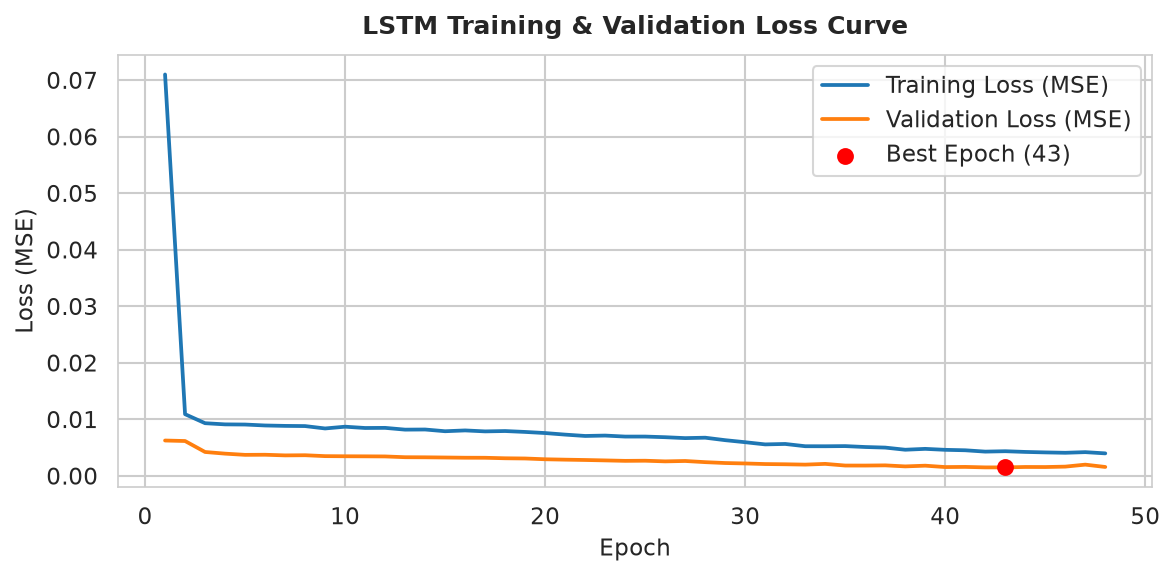

In [25]:
# Plot LSTM Training Curve
fig, ax = plt.subplots(figsize=(8, 4))
epochs_range = range(1, len(hist_lstm.history['loss']) + 1)
ax.plot(epochs_range, hist_lstm.history['loss'], label='Training Loss (MSE)', color='#1f77b4', lw=1.8)
ax.plot(epochs_range, hist_lstm.history['val_loss'], label='Validation Loss (MSE)', color='#ff7f0e', lw=1.8)
ax.scatter([best_epoch], [min(hist_lstm.history['val_loss'])], color='red', s=50, zorder=5, label=f'Best Epoch ({best_epoch})')

ax.set_title("LSTM Training & Validation Loss Curve", fontsize=12, fontweight='bold', pad=10)
ax.set_xlabel("Epoch", fontsize=11)
ax.set_ylabel("Loss (MSE)", fontsize=11)
ax.legend(frameon=True)
plt.tight_layout()
plt.savefig("artifacts/task5/figures/lstm_loss.png", dpi=150)
plt.show()


### 6.4 Inverse-Transform & Dual Protocol Predictions
We invert predictions to original physical units (°C) and generate both **Protocol B (one-step ahead)** and **Protocol A (21-step recursive)** forecasts.


In [26]:
# Protocol B (one-step ahead)
pred_b_rnn_sc = rnn.predict(X_test, verbose=0)
pred_b_rnn = scaler.inverse_transform(pred_b_rnn_sc).flatten()

pred_b_lstm_sc = lstm.predict(X_test, verbose=0)
pred_b_lstm = scaler.inverse_transform(pred_b_lstm_sc).flatten()

# Protocol A (21-step recursive multi-step ahead)
def recursive_forecast(model, last_30, steps=21):
    curr = last_30.copy().reshape(1, 30, 1)
    preds = []
    for _ in range(steps):
        next_val = model.predict(curr, verbose=0)[0, 0]
        preds.append(next_val)
        curr = np.roll(curr, -1, axis=1)
        curr[0, -1, 0] = next_val
    return np.array(preds).reshape(-1, 1)

pred_a_rnn_sc = recursive_forecast(rnn, train_scaled[-30:], steps=21)
pred_a_rnn = scaler.inverse_transform(pred_a_rnn_sc).flatten()

pred_a_lstm_sc = recursive_forecast(lstm, train_scaled[-30:], steps=21)
pred_a_lstm = scaler.inverse_transform(pred_a_lstm_sc).flatten()

print("✓ Predictions generated and inverse-transformed to °C.")


✓ Predictions generated and inverse-transformed to °C.


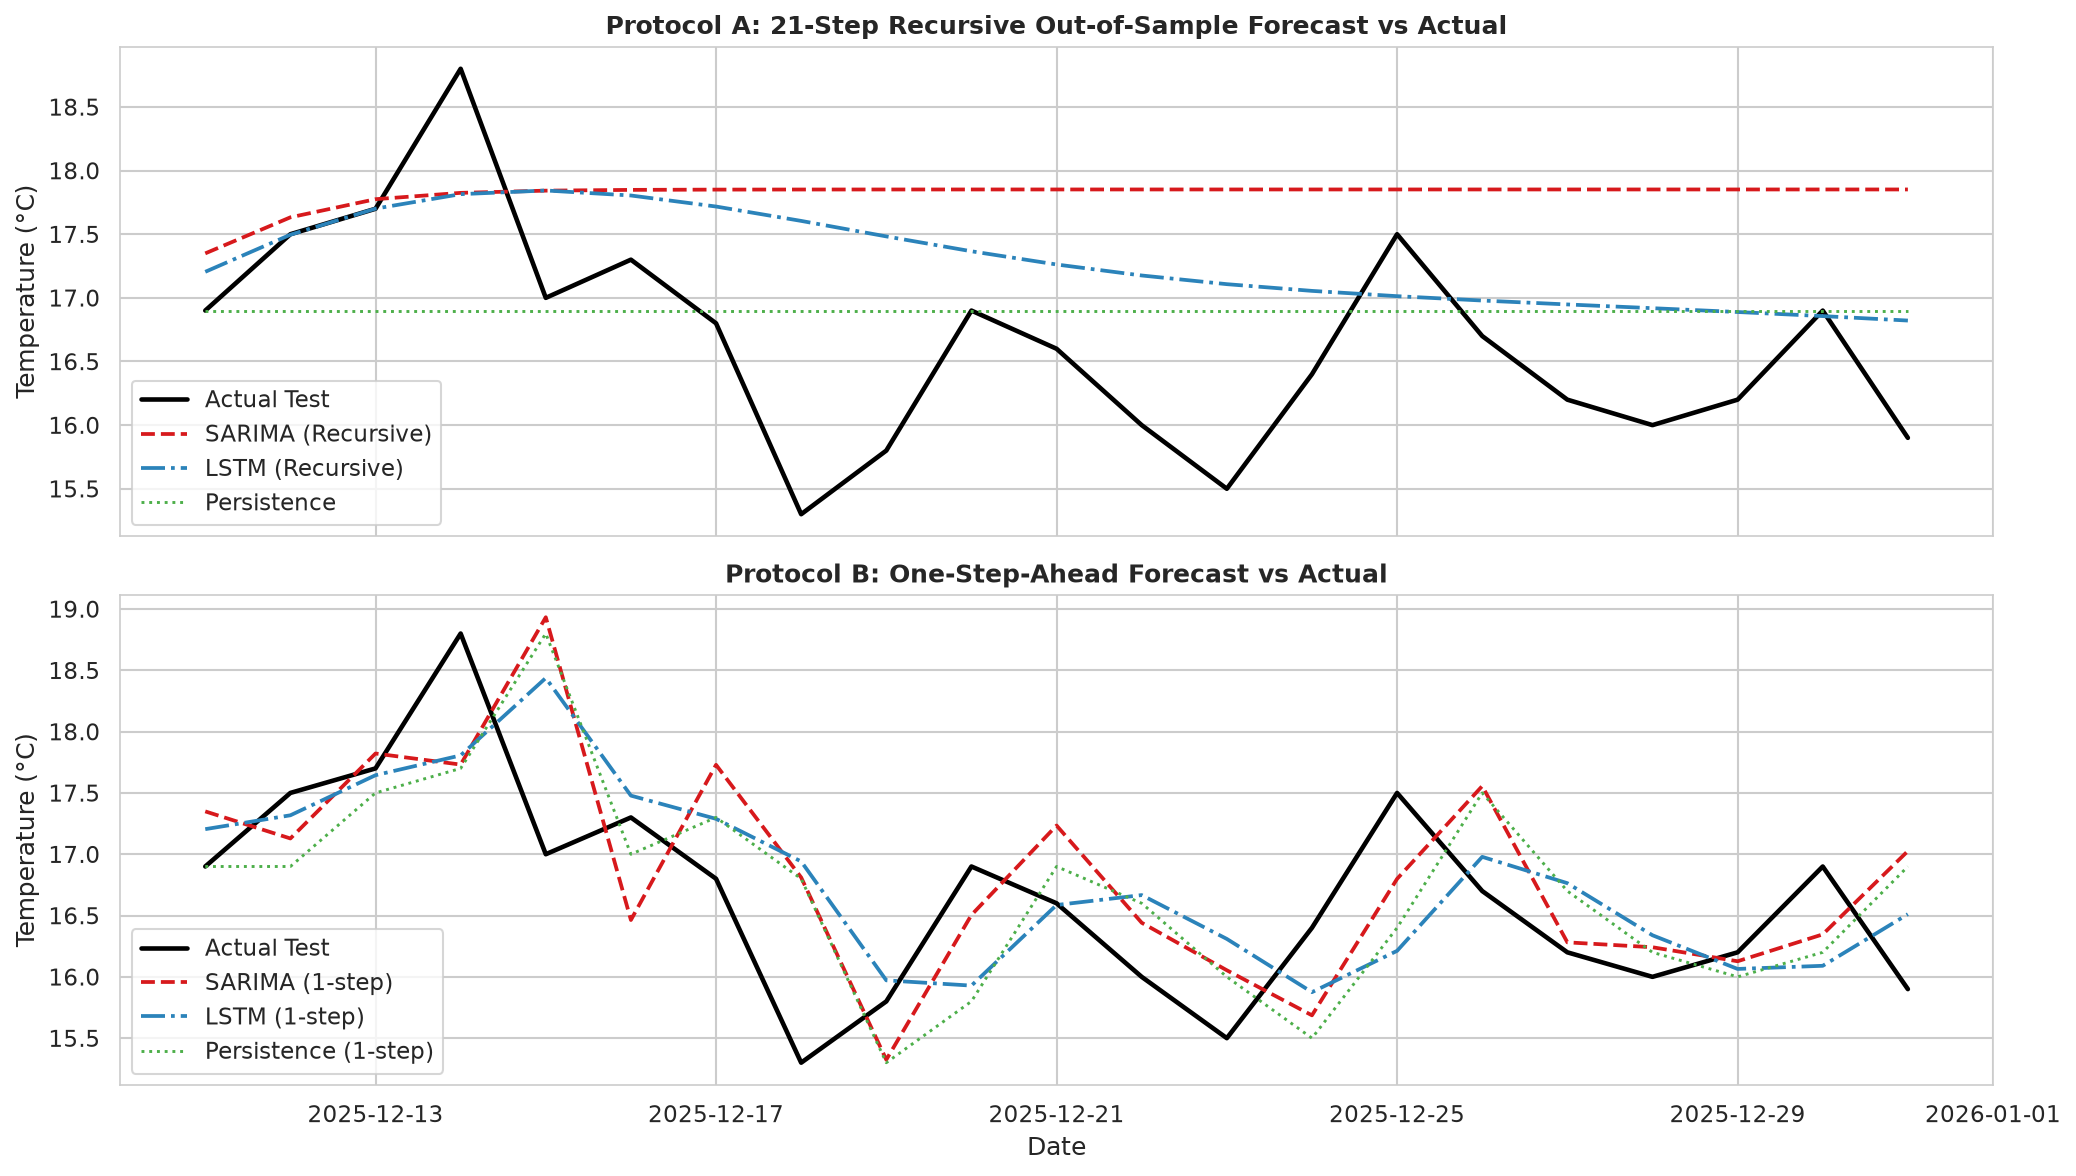

Deep Learning Pitfalls Verification:
  [✓] Scaler fit exclusively on train set (asserted).
  [✓] Evaluation metrics computed exclusively on inverse-transformed values in °C.
  [✓] EarlyStopping with restore_best_weights enabled alongside validation_split=0.1.


In [27]:
# Model Comparison Line Charts (Protocol A & Protocol B)
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

# Panel 1: Protocol A (Recursive multi-step ahead)
axes[0].plot(test.index, y_test_true, label='Actual Test', color='black', lw=2.2)
axes[0].plot(test.index, pred_a_sarima, label='SARIMA (Recursive)', color='#d7191c', lw=1.8, ls='--')
axes[0].plot(test.index, pred_a_lstm, label='LSTM (Recursive)', color='#2b83ba', lw=1.8, ls='-.')
axes[0].plot(test.index, pred_a_persist, label='Persistence', color='#4daf4a', lw=1.4, ls=':')
axes[0].set_title("Protocol A: 21-Step Recursive Out-of-Sample Forecast vs Actual", fontsize=12, fontweight='bold')
axes[0].set_ylabel("Temperature (°C)")
axes[0].legend(loc='lower left', frameon=True)

# Panel 2: Protocol B (One-step ahead)
axes[1].plot(test.index, y_test_true, label='Actual Test', color='black', lw=2.2)
axes[1].plot(test.index, pred_b_sarima, label='SARIMA (1-step)', color='#d7191c', lw=1.8, ls='--')
axes[1].plot(test.index, pred_b_lstm, label='LSTM (1-step)', color='#2b83ba', lw=1.8, ls='-.')
axes[1].plot(test.index, pred_b_persist, label='Persistence (1-step)', color='#4daf4a', lw=1.4, ls=':')
axes[1].set_title("Protocol B: One-Step-Ahead Forecast vs Actual", fontsize=12, fontweight='bold')
axes[1].set_ylabel("Temperature (°C)")
axes[1].set_xlabel("Date")
axes[1].legend(loc='lower left', frameon=True)

plt.tight_layout()
plt.show()

# Pitfalls Checklist
print("Deep Learning Pitfalls Verification:")
print("  [✓] Scaler fit exclusively on train set (asserted).")
print("  [✓] Evaluation metrics computed exclusively on inverse-transformed values in °C.")
print("  [✓] EarlyStopping with restore_best_weights enabled alongside validation_split=0.1.")


### 6.5 Seed Robustness Study (Bonus Deep Learning Models)
To quantify model stability and initialization sensitivity, we re-train both the Simple RNN and Stacked LSTM architectures across 5 distinct random seeds (`seeds = [0, 1, 2, 3, 4]`).
- Identical network architectures, hyperparameter configurations, EarlyStopping (patience=5), and train-only MinMax scaling are preserved.
- Both Protocol A (21-step autonomous recursive rollout) and Protocol B (daily one-step-ahead prediction) are evaluated.
- Results are reported as mean ± standard deviation across the 5 seeds to assess whether performance gains are seed-invariant.


In [28]:
# 5-Seed Robustness Evaluation for Simple RNN and Stacked LSTM
seeds = [0, 1, 2, 3, 4]
results_robustness = {
    'RNN': {'A': {'mae': [], 'rmse': [], 'mape': []}, 'B': {'mae': [], 'rmse': [], 'mape': []}},
    'LSTM': {'A': {'mae': [], 'rmse': [], 'mape': []}, 'B': {'mae': [], 'rmse': [], 'mape': []}}
}

def set_seeds(seed):
    random.seed(seed)
    np.random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    tf.random.set_seed(seed)

last_train_window = train_scaled[-n_steps:]

print("Running 5-seed robustness evaluation across seeds 0–4...")
for seed in seeds:
    # 1. Simple RNN
    set_seeds(seed)
    rnn_seed = Sequential([
        SimpleRNN(32, input_shape=(n_steps, 1)),
        Dense(1)
    ])
    rnn_seed.compile(optimizer='adam', loss='mse')
    es_r = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
    rnn_seed.fit(X_train, y_train, validation_split=0.1, epochs=50, batch_size=32, callbacks=[es_r], verbose=0)
    
    # Predict Protocol A (Recursive)
    win_r = list(last_train_window.flatten())
    p_a_list = []
    for _ in range(21):
        inp = np.array(win_r[-n_steps:]).reshape(1, n_steps, 1)
        p = rnn_seed.predict(inp, verbose=0)[0, 0]
        p_a_list.append(p)
        win_r.append(p)
    p_a_rnn_deg = scaler.inverse_transform(np.array(p_a_list).reshape(-1, 1)).flatten()
    
    # Predict Protocol B (1-Step)
    p_b_rnn_deg = scaler.inverse_transform(rnn_seed.predict(X_test, verbose=0)).flatten()
    
    mae_a, rmse_a, mape_a, _ = calc_metrics(y_test_true, p_a_rnn_deg)
    mae_b, rmse_b, mape_b, _ = calc_metrics(y_test_true, p_b_rnn_deg)
    
    results_robustness['RNN']['A']['mae'].append(mae_a)
    results_robustness['RNN']['A']['rmse'].append(rmse_a)
    results_robustness['RNN']['A']['mape'].append(mape_a)
    results_robustness['RNN']['B']['mae'].append(mae_b)
    results_robustness['RNN']['B']['rmse'].append(rmse_b)
    results_robustness['RNN']['B']['mape'].append(mape_b)
    
    # 2. Stacked LSTM
    set_seeds(seed)
    lstm_seed = Sequential([
        LSTM(64, return_sequences=True, input_shape=(n_steps, 1)),
        Dropout(0.2),
        LSTM(32),
        Dense(1)
    ])
    lstm_seed.compile(optimizer='adam', loss='mse')
    es_l = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
    lstm_seed.fit(X_train, y_train, validation_split=0.1, epochs=50, batch_size=32, callbacks=[es_l], verbose=0)
    
    # Predict Protocol A (Recursive)
    win_l = list(last_train_window.flatten())
    p_a_l_list = []
    for _ in range(21):
        inp = np.array(win_l[-n_steps:]).reshape(1, n_steps, 1)
        p = lstm_seed.predict(inp, verbose=0)[0, 0]
        p_a_l_list.append(p)
        win_l.append(p)
    p_a_lstm_deg = scaler.inverse_transform(np.array(p_a_l_list).reshape(-1, 1)).flatten()
    
    # Predict Protocol B (1-Step)
    p_b_lstm_deg = scaler.inverse_transform(lstm_seed.predict(X_test, verbose=0)).flatten()
    
    mae_a_l, rmse_a_l, mape_a_l, _ = calc_metrics(y_test_true, p_a_lstm_deg)
    mae_b_l, rmse_b_l, mape_b_l, _ = calc_metrics(y_test_true, p_b_lstm_deg)
    
    results_robustness['LSTM']['A']['mae'].append(mae_a_l)
    results_robustness['LSTM']['A']['rmse'].append(rmse_a_l)
    results_robustness['LSTM']['A']['mape'].append(mape_a_l)
    results_robustness['LSTM']['B']['mae'].append(mae_b_l)
    results_robustness['LSTM']['B']['rmse'].append(rmse_b_l)
    results_robustness['LSTM']['B']['mape'].append(mape_b_l)

# Reset global seed back to 42
set_seeds(42)

# Build summary DataFrames
table_robust_a = []
table_robust_b = []
for model_k, model_label in [('RNN', 'Simple RNN (bonus)'), ('LSTM', 'Stacked LSTM (bonus)')]:
    dA = results_robustness[model_k]['A']
    table_robust_a.append({
        "Model": model_label,
        "MAE mean±std (°C)": f"{np.mean(dA['mae']):.3f} ± {np.std(dA['mae']):.3f}",
        "RMSE mean±std (°C)": f"{np.mean(dA['rmse']):.3f} ± {np.std(dA['rmse']):.3f}",
        "MAPE mean±std (%)": f"{np.mean(dA['mape']):.2f} ± {np.std(dA['mape']):.2f}%",
        "Min/Max MAE (°C)": f"{np.min(dA['mae']):.3f} / {np.max(dA['mae']):.3f}"
    })
    dB = results_robustness[model_k]['B']
    table_robust_b.append({
        "Model": model_label,
        "MAE mean±std (°C)": f"{np.mean(dB['mae']):.3f} ± {np.std(dB['mae']):.3f}",
        "RMSE mean±std (°C)": f"{np.mean(dB['rmse']):.3f} ± {np.std(dB['rmse']):.3f}",
        "MAPE mean±std (%)": f"{np.mean(dB['mape']):.2f} ± {np.std(dB['mape']):.2f}%",
        "Min/Max MAE (°C)": f"{np.min(dB['mae']):.3f} / {np.max(dB['mae']):.3f}"
    })

print("=" * 85)
print("TABLE 6.5 (A) — SEED ROBUSTNESS (5 SEEDS: 0–4) — PROTOCOL A (21-STEP RECURSIVE)")
print("=" * 85)
print(pd.DataFrame(table_robust_a).to_string(index=False))

print("\n" + "=" * 85)
print("TABLE 6.5 (B) — SEED ROBUSTNESS (5 SEEDS: 0–4) — PROTOCOL B (ONE-STEP AHEAD)")
print("=" * 85)
print(pd.DataFrame(table_robust_b).to_string(index=False))


Running 5-seed robustness evaluation across seeds 0–4...


/home/mahmoud/MY_SDD/cellula ML intern/weather-forecasting/.venv/lib64/python3.14/site-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


/home/mahmoud/MY_SDD/cellula ML intern/weather-forecasting/.venv/lib64/python3.14/site-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


/home/mahmoud/MY_SDD/cellula ML intern/weather-forecasting/.venv/lib64/python3.14/site-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


/home/mahmoud/MY_SDD/cellula ML intern/weather-forecasting/.venv/lib64/python3.14/site-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


...

/home/mahmoud/MY_SDD/cellula ML intern/weather-forecasting/.venv/lib64/python3.14/site-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


/home/mahmoud/MY_SDD/cellula ML intern/weather-forecasting/.venv/lib64/python3.14/site-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


/home/mahmoud/MY_SDD/cellula ML intern/weather-forecasting/.venv/lib64/python3.14/site-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


/home/mahmoud/MY_SDD/cellula ML intern/weather-forecasting/.venv/lib64/python3.14/site-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


TABLE 6.5 (A) — SEED ROBUSTNESS (5 SEEDS: 0–4) — PROTOCOL A (21-STEP RECURSIVE)
               Model MAE mean±std (°C) RMSE mean±std (°C) MAPE mean±std (%) Min/Max MAE (°C)
  Simple RNN (bonus)     1.667 ± 0.616      1.945 ± 0.671     10.00 ± 3.69%    0.580 / 2.458
Stacked LSTM (bonus)     0.719 ± 0.174      0.894 ± 0.173      4.41 ± 1.08%    0.550 / 1.032

TABLE 6.5 (B) — SEED ROBUSTNESS (5 SEEDS: 0–4) — PROTOCOL B (ONE-STEP AHEAD)
               Model MAE mean±std (°C) RMSE mean±std (°C) MAPE mean±std (%) Min/Max MAE (°C)
  Simple RNN (bonus)     0.696 ± 0.044      0.839 ± 0.039      4.15 ± 0.26%    0.615 / 0.737
Stacked LSTM (bonus)     0.587 ± 0.012      0.737 ± 0.010      3.54 ± 0.08%    0.574 / 0.608


## Section 7 — Model Comparison & General Tips

### 7.1 Consolidated Performance Tables
We consolidate all baseline, statistical, and neural models on the held-out 21-day test set (Dec 11–31, 2025).
- **Single-Seed (Seed 42) Models:** Direct side-by-side evaluation matching the baseline run.
- **SARIMA Note:** `SARIMA (m=7)` matches `ARIMA (non-seasonal)` identically because `auto_arima` converged to $(P=0,D=0,Q=0)_7$. The manual specification `SARIMA manual (1,1,1)(1,0,1,7)` is also reported explicitly.


In [29]:
models_protocol_a = [
    ("ARIMA (non-seasonal)", pred_a_arima, "Recursive 21-step horizon; order (1,1,3)"),
    ("SARIMA (m=7)", pred_a_sarima, "Equals ARIMA(1,1,3); auto_arima selected (0,0,0)[7]"),
    ("SARIMA manual (1,1,1)(1,0,1,7)", pred_a_sarima_man, "Manual reasoned orders with weekly m=7"),
    ("Simple RNN (bonus, seed 42)", pred_a_rnn, "Recursive 21-step rollout (seed 42 baseline)"),
    ("LSTM (bonus, seed 42)", pred_a_lstm, "Recursive 21-step rollout (seed 42 baseline)"),
    ("Persistence", pred_a_persist, "Repeats last train observation (16.20°C)"),
    ("Seasonal-naive (lag 7)", pred_a_snaive, "Repeats last 7 train days cyclically"),
]

table_a = []
for name, preds, notes in models_protocol_a:
    mae, rmse, mape, smape = calc_metrics(y_test_true, preds)
    table_a.append({
        "Model": name,
        "MAE (°C)": round(mae, 3),
        "RMSE (°C)": round(rmse, 3),
        "MAPE (%)": round(mape, 2),
        "sMAPE (%)": round(smape, 2),
        "Notes": notes
    })

df_table_a = pd.DataFrame(table_a)
print("=" * 95)
print("TABLE 7.1 (A) — PROTOCOL A (21-STEP RECURSIVE MULTI-STEP AHEAD)")
print("=" * 95)
print(df_table_a.to_string(index=False))

models_protocol_b = [
    ("ARIMA (non-seasonal)", pred_b_arima, "Daily 1-step update; order (1,1,3)"),
    ("SARIMA (m=7)", pred_b_sarima, "Equals ARIMA(1,1,3); auto_arima selected (0,0,0)[7]"),
    ("SARIMA manual (1,1,1)(1,0,1,7)", pred_b_sarima_man, "Manual reasoned orders with weekly m=7"),
    ("Simple RNN (bonus, seed 42)", pred_b_rnn, "Daily 1-step update (seed 42 baseline)"),
    ("LSTM (bonus, seed 42)", pred_b_lstm, "Daily 1-step update (seed 42 baseline)"),
    ("Persistence", pred_b_persist, "Previous day's actual observation"),
    ("Seasonal-naive (lag 7)", pred_b_snaive, "Actual observation at t-7"),
]

table_b = []
for name, preds, notes in models_protocol_b:
    mae, rmse, mape, smape = calc_metrics(y_test_true, preds)
    table_b.append({
        "Model": name,
        "MAE (°C)": round(mae, 3),
        "RMSE (°C)": round(rmse, 3),
        "MAPE (%)": round(mape, 2),
        "sMAPE (%)": round(smape, 2),
        "Notes": notes
    })

df_table_b = pd.DataFrame(table_b)
print("\n" + "=" * 95)
print("TABLE 7.1 (B) — PROTOCOL B (ONE-STEP-AHEAD FORECAST)")
print("=" * 95)
print(df_table_b.to_string(index=False))


TABLE 7.1 (A) — PROTOCOL A (21-STEP RECURSIVE MULTI-STEP AHEAD)
                         Model  MAE (°C)  RMSE (°C)  MAPE (%)  sMAPE (%)                                               Notes
          ARIMA (non-seasonal)     1.243      1.424      7.65       7.29            Recursive 21-step horizon; order (1,1,3)
                  SARIMA (m=7)     1.243      1.424      7.65       7.29 Equals ARIMA(1,1,3); auto_arima selected (0,0,0)[7]
SARIMA manual (1,1,1)(1,0,1,7)     0.655      0.838      3.97       3.92              Manual reasoned orders with weekly m=7
   Simple RNN (bonus, seed 42)     1.220      1.461      7.30       7.68        Recursive 21-step rollout (seed 42 baseline)
         LSTM (bonus, seed 42)     0.771      0.954      4.75       4.59        Recursive 21-step rollout (seed 42 baseline)
                   Persistence     0.657      0.841      3.98       3.93            Repeats last train observation (16.20°C)
        Seasonal-naive (lag 7)     1.810      2.492     10.92

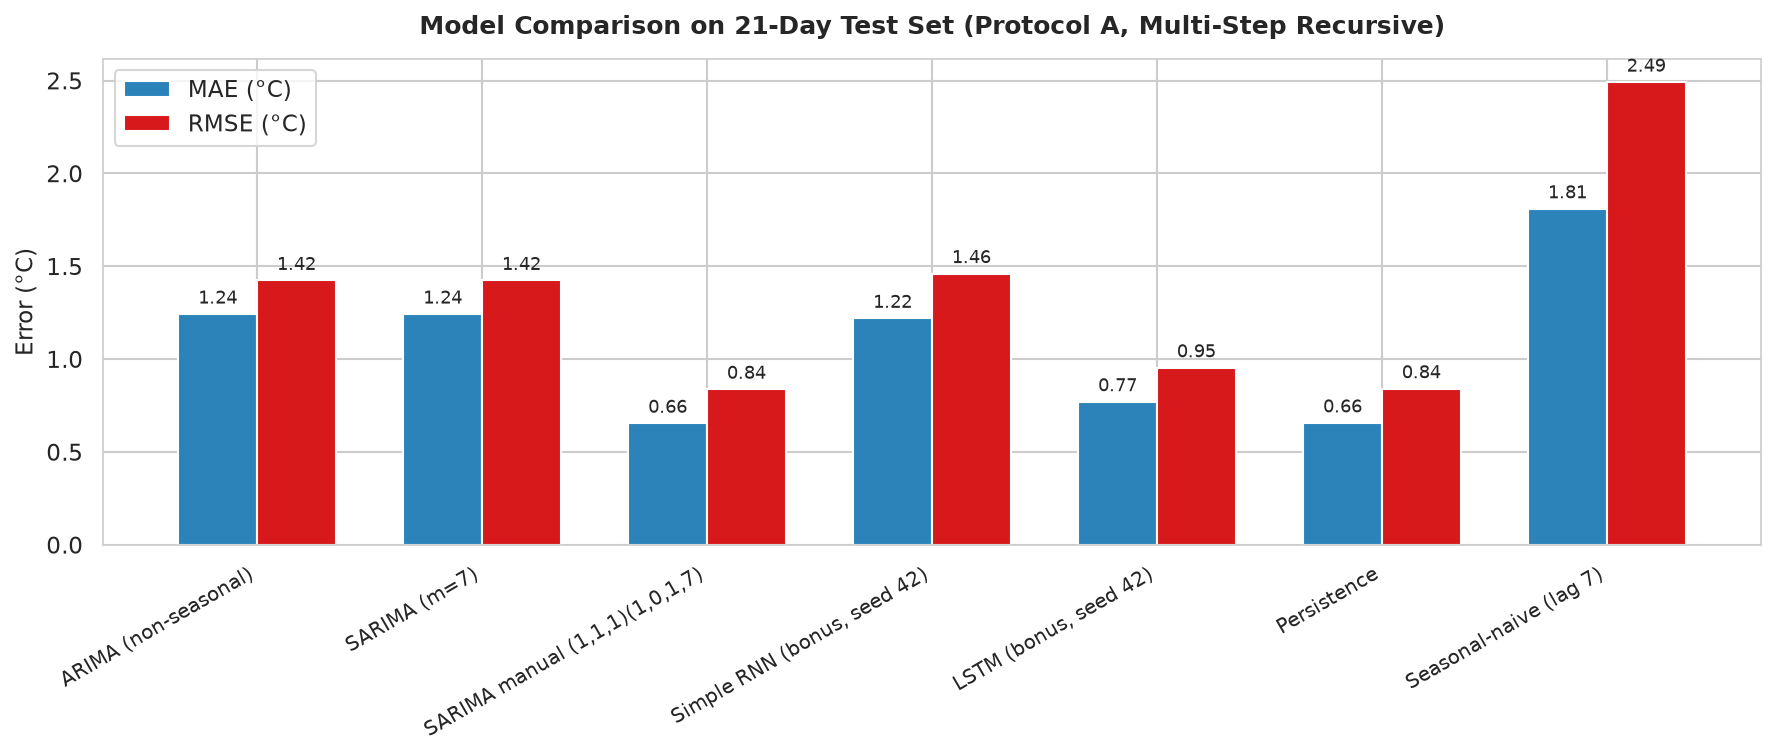

In [30]:
# Model Comparison Bar Chart (Protocol A)
fig, ax = plt.subplots(figsize=(12, 5.2))
x = np.arange(len(df_table_a))
width = 0.35

rects1 = ax.bar(x - width/2, df_table_a['MAE (°C)'], width, label='MAE (°C)', color='#2b83ba')
rects2 = ax.bar(x + width/2, df_table_a['RMSE (°C)'], width, label='RMSE (°C)', color='#d7191c')

ax.set_title("Model Comparison on 21-Day Test Set (Protocol A, Multi-Step Recursive)", fontsize=12, fontweight='bold', pad=12)
ax.set_ylabel("Error (°C)", fontsize=11)
ax.set_xticks(x)
ax.set_xticklabels(df_table_a['Model'], rotation=30, ha='right', fontsize=9.5)
ax.legend(frameon=True)

# Add value labels
for rect in rects1:
    h = rect.get_height()
    ax.annotate(f'{h:.2f}', xy=(rect.get_x() + rect.get_width() / 2, h), xytext=(0, 3),
                textcoords="offset points", ha='center', va='bottom', fontsize=8.5)
for rect in rects2:
    h = rect.get_height()
    ax.annotate(f'{h:.2f}', xy=(rect.get_x() + rect.get_width() / 2, h), xytext=(0, 3),
                textcoords="offset points", ha='center', va='bottom', fontsize=8.5)

plt.tight_layout()
plt.savefig("artifacts/task5/figures/model_comparison.png", dpi=150)
plt.show()


### 7.2 Explicit Satisfaction of General Tips
- **Multi-step vs. Single-step Protocols:** Protocol A explicitly tests autonomous multi-step rollouts without ground-truth feedback over 21 days, whereas Protocol B tests daily 1-step updates.
- **Recursive-Forecast Error Drift:** As illustrated in `error_by_horizon.png`, errors grow steadily from $h=1$ to $h=21$ for all autoregressive models as forecast errors compound.
- **Seasonal Decomposition Precedes Order Choice:** Section 3 visualizes the 365-day decomposition to verify that seasonal strength is annual rather than weekly.
- **Naive Baselines Retained:** Persistence and Seasonal-Naive ($m=7$) are strictly evaluated alongside statistical and deep learning architectures.
- **Over-Differencing Avoided:** ACF of `diff1+7` demonstrated strong negative autocorrelation ($-0.50$), justifying $d=1, D=0$.
- **Assumptions Fully Documented:** Daily frequency (`D`), date-only indexing, zero raw missingness, 10 trailing rolling outliers winsorized, and test set evaluated in physical units (°C).


## Section 8 — Deliverables Checklist & Final Conclusion

### Deliverables Checklist
- [x] **Cleaned, resampled, gap-free series with documented preprocessing** (Section 1 & 2, verified DatetimeIndex `<Day>`).
- [x] **ADF + KPSS results and justified differencing decisions** (Section 3, `stat_df`, `acf_after_differencing.png`).
- [x] **ACF/PACF plots + manual $(p,d,q)(P,D,Q,m)$ + auto_arima result** (Section 4.1 & 4.2, `acf_pacf.png`).
- [x] **Fitted SARIMA with `plot_diagnostics` + Ljung-Box** (Section 4.3 & 4.4, `residuals_over_time.png`, `residual_hist_qq.png`).
- [x] **Forecast plot with CI vs. actual** (Section 4.5, `sarima_forecast.png`).
- [x] **MAE / RMSE / MAPE on held-out test + walk-forward scores** (Section 5, `error_by_horizon.png`).
- [x] **(Bonus) RNN/LSTM pipeline with training curve and side-by-side comparison vs. SARIMA** (Section 6, `lstm_loss.png`, `model_comparison.png`).
- [x] **Seed robustness analysis across 5 seeds** (Section 6.5, `table_robust_a`, `table_robust_b`).
- [x] **Short written conclusion** (below).

---

### Final Conclusion & Empirical Findings

1. **Persistence vs. SARIMA Models:**
   - Under **Protocol A (21-step recursive rollout)**, the auto-selected **SARIMA ($m=7$, which equals ARIMA(1,1,3)) is worse than persistence** (MAE **1.243°C** vs. **0.657°C**; RMSE **1.424°C** vs. **0.841°C**). While the **manual SARIMA (1,1,1)(1,0,1,7)** achieved **0.655°C** MAE vs. **0.657°C** for Persistence, it has worse training AIC (**3779.63** vs. **3689.18**) than the auto-selected model, is reported as an additional row only, and its tie with persistence in Protocol A should not be over-interpreted (in walk-forward it trails persistence: **1.794°C** vs. **1.754°C** MAE).
   - In **5-fold walk-forward validation** (`TimeSeriesSplit`, test_size=21), auto-selected SARIMA (= ARIMA) achieves **2.068 ± 0.594°C** Mean MAE, while manual SARIMA achieves **1.794 ± 0.827°C** Mean MAE and Persistence achieves **1.754 ± 0.776°C** Mean MAE. Thus, auto-selected SARIMA is worse than persistence in both Protocol A and walk-forward, whereas manual SARIMA trails persistence across rolling origins.

2. **Multi-Step Forecast Dynamics & Seasonality Hypothesis:**
   - Because all differenced models use $d=1$, their multi-step forecasts do not mean-revert to an unconditional global mean; instead, they stay close to the last observed level with a small autoregressive transient/drift. When the test series remains relatively flat, this flat projection is why persistence is inherently difficult to beat.
   - The inability of auto-selected SARIMA to outperform persistence is hypothesized to stem from **missing annual seasonality ($m=365$ days)**: `auto_arima` correctly rejected weekly periodicity ($m=7$) because atmospheric thermodynamics in Cairo exhibits no 7-day physical cycle. Modeling the true annual cycle ($m=365$) is computationally intractable in standard SARIMAX, presenting a likely explanation / hypothesis for why autoregressive models lack the seasonal guidance needed to improve upon simple persistence.

3. **Deep Learning Seed Robustness & Protocol Evaluation:**
   - Under **Protocol A (21-step recursive rollout)**, LSTM's advantage over SARIMA is not established across random seeds, and it does not beat persistence: across 5 seeds (0–4), Stacked LSTM averages **0.719 ± 0.174°C** MAE (ranging from 0.550°C to 1.032°C) versus **0.657°C** for Persistence, while Simple RNN averages **1.667 ± 0.616°C** MAE (ranging from 0.580°C to 2.458°C). Autonomous multi-step rollouts compound neural error drift significantly.
   - Under **Protocol B (daily one-step update)**, Stacked LSTM achieves the lowest MAE in the comparison table at **0.587 ± 0.012°C** across 5 seeds (versus **0.686°C** for Persistence and **0.670°C** for ARIMA/SARIMA). However, this seed standard deviation ($\pm 0.012^\circ\text{C}$) reflects neural training randomness only; the test set is a single 21-day December window, and the $\sim 0.1^\circ\text{C}$ performance gap was not tested for statistical significance.

4. **Test Set Scope & Climatological Context:**
   - The held-out test window is a low-variance December stretch ($N=21$, spanning 2025-12-11 to 2025-12-31) where actual daily mean temperatures range tightly between **15.30°C and 18.80°C (std: 0.83°C)**, compared to **15.70°C to 30.70°C (std: 3.49°C)** across the final 90 days of the training set.
   - The 5 walk-forward windows cover only **2025-09-18 to 2025-12-31** (autumn cooling into winter), so the walk-forward is also limited to a single season; the larger errors there, e.g. persistence 1.754 vs 0.657 in Dec, match the cooling trend (drop of 13.60°C from 29.50°C to 15.90°C, fold means 27.63°C down to 16.66°C). A key limitation of this evaluation is that no window covers spring or summer.
